# Proyecto final · Aprendizaje Automático de Máquina I

Notebook completo: reúne, en orden, todas las etapas del proyecto. Cada etapa guarda sus resultados en disco y la siguiente los lee de allí.

1. Datos
2. Exploración
3. Cribado de análisis
4. Regresión
5. Clasificación y Bayes
6. Agrupamiento
7. Evaluación final

## Código del proyecto

La celda siguiente recrea el paquete `proyecto/` dentro de la sesión, de forma que el notebook funciona en Google Colab sin clonar ningún repositorio: basta con ejecutarla una vez (*Entorno de ejecución → Ejecutar todas*). En una copia local del repositorio no reemplaza ningún archivo. La sección puede plegarse desde su título.

In [ ]:
# Código del proyecto. Esta celda recrea en el directorio de trabajo:
#   - el paquete `proyecto/` (49 módulos) y `configuracion/mapeo_columnas.json`;
# para que el notebook funcione en Google Colab sin clonar el repositorio. Todo viaja
# al final de la celda como un .tar.xz en base64 (60 archivos, 177 kB).
# Antes de extraer se comprueba su huella SHA-256. Un archivo que ya existe con el
# mismo contenido no se toca, y uno que existe con otro contenido (una copia local
# del repositorio con cambios, por ejemplo) se conserva y se avisa; para
# reemplazarlo hay que poner SOBRESCRIBIR = True.
import base64
import hashlib
import importlib
import io
import os
import sys
import tarfile
from pathlib import Path

SOBRESCRIBIR = False


def recrear_proyecto(huella, codificado):
    datos = base64.b64decode(codificado)
    if hashlib.sha256(datos).hexdigest() != huella:
        raise ValueError("El código embebido está dañado: su SHA-256 no coincide.")
    escritos, iguales, conservados = 0, 0, []
    with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
        for miembro in archivo.getmembers():
            nombre = miembro.name
            if Path(nombre).is_absolute() or ".." in Path(nombre).parts:
                raise ValueError(f"Ruta no permitida en el archivo: {nombre}")
            contenido, destino = archivo.extractfile(miembro).read(), Path(nombre)
            if destino.exists() and destino.read_bytes() == contenido:
                iguales += 1
            elif destino.exists() and not SOBRESCRIBIR:
                conservados.append(nombre)
            else:
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(contenido)
                escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print(f"Código del proyecto: {escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto(
    huella="a2d58283cc5d54a9eaafe99d0447eab556292aad1e7bcd59c2b58d8adb8961f3",
    codificado="...",
)

# 01 · Datos: el problema y el conjunto de datos

Esta etapa plantea el problema, presenta el conjunto de datos (qué tablas y columnas se esperan y en
qué momento del proceso se conoce cada una) y entrega las tablas crudas con las que trabaja el resto
del proyecto, sin limpiar nada todavía.

In [1]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import datos

iniciar_etapa("01_datos")
c = datos.iniciar()
mostrar(c.encabezado, c.autores)

## 1. El problema

Un laboratorio de microbiología recibe a diario muestras de producto terminado, materia prima, agua
y muestreos en planta de clientes de los sectores cosmético, farmacéutico, de alimentos, veterinario
y de centrales de mezclas, y de cada muestra guarda quién la envió, en qué condiciones llegó, qué
ensayo se le hizo, quién la procesó y cuál fue el resultado (contexto de empresa: Rodam Análisis
SAS, Bogotá; el objeto de estudio es la base de muestras, no la empresa). Con esa base se plantean
tres preguntas:

- **Anticipar la demanda:** cuántas muestras van a llegar, para programar analistas, medios e
  incubadoras.
- **Estimar el riesgo de cada resultado:** qué tan probable es que una muestra resulte no conforme
  y, si sale positiva, que se trate de un falso positivo.
- **Entender los grupos:** qué clientes o muestras se parecen entre sí.

De cada pregunta salen varios análisis posibles, de forma que el proyecto declara un catálogo de
candidatos, los somete a la misma prueba rápida (etapa 03) y solo estudia a fondo a los ganadores.

## 2. El contrato de datos

El contrato (`proyecto/datos/esquema.py`) es la única fuente de verdad sobre los nombres de
columna: de cada una declara su tipo, su papel, si es obligatoria y el **momento** del proceso en que
el dato pasa a conocerse. Si la exportación real no trae una columna opcional, los análisis que la
usan simplemente se omiten.

El momento es lo que más adelante impide la fuga de información: cada análisis declara en qué
momento se hace la predicción, y sus variables solo pueden ser columnas conocidas hasta ese momento.

In [2]:
datos.contrato(c).mostrar()

Columna,Tipo,Papel,Momento,Obligatoria,Descripción
id_cliente,id,id,maestro,sí,Identificador del cliente
sector,categoria,variable,maestro,sí,Línea de negocio del cliente
zona,categoria,variable,maestro,no,Municipio o zona de la planta
tamano,categoria,variable,maestro,no,Tamaño de la empresa
tipo_contrato,categoria,variable,maestro,no,Contrato marco o servicio por demanda
certificacion_bpm,categoria,variable,maestro,no,Cuenta con certificación BPM (sí/no)
plan_muestreo,categoria,variable,maestro,no,Frecuencia pactada de muestreo en planta
fecha_vinculacion,fecha,fecha,maestro,no,Fecha de vinculación como cliente
distancia_km,numero,variable,maestro,no,Distancia de la planta al laboratorio (km)
canal_captacion,categoria,variable,maestro,no,Canal por el que llegó el cliente


## 3. Las tablas crudas

Se obtienen las tablas, se validan contra el contrato (si falta una columna obligatoria la etapa se
detiene con la lista completa) y se guardan tal como llegan, en CSV, de forma que la limpieza de la
etapa 02 quede como un paso aparte y auditable.

In [3]:
datos.tablas_crudas(c).mostrar()

### Cómo llegan los datos

Basta mirar las tablas para ver por qué hace falta una etapa de limpieza: la misma categoría
escrita de varias formas, recuentos reportados como texto, valores imposibles y filas repetidas.

In [4]:
datos.como_llegan(c).mostrar()

## 4. De dónde salen los datos y cómo se conecta la exportación real

La exportación real todavía no está disponible, de forma que mientras tanto las tablas salen de un
simulador que reproduce el recorrido de cada muestra por el laboratorio (con la misma «suciedad»);
las variables latentes que usa (si la muestra estaba de verdad contaminada, la higiene del cliente)
se guardan aparte en `datos/auditoria/` y ningún modelo las lee. Para usar los datos reales basta
copiar los archivos en `datos/reales/`, describir en `configuracion/mapeo_columnas.json` cómo se
llama cada columna y cada etiqueta, y fijar `PROYECTO_ORIGEN=real`, sin tocar el código.

In [5]:
datos.exportacion_real(c).mostrar()

Tabla de auditoría,Filas,Columnas latentes
verdad_muestras,38846,"contaminada_real, prob_contaminacion, prob_falso_positivo, positivo_sin_ruido, en_episodio, logit_contaminacion"
verdad_clientes,220,"segmento_latente, higiene, tasa_semanal, fecha_retiro"
verdad_ensayos,7,"ensayo, sensibilidad, especificidad_nominal, especificidad_efectiva, prevalencia_real"


## 5. Protocolo de evaluación y mapa del proyecto

La partición es por tiempo, con cortes fijados en `config` antes de mirar resultados:
**entrenamiento** para ajustar y comparar (validación cruzada de ventana creciente),
**validación** para decidir (umbral, modelo que se congela) y **prueba**, que se guarda aparte y se
abre una sola vez en la etapa 07. Las etapas solo se comunican por archivos en disco.

In [6]:
datos.protocolo(c).mostrar()

In [7]:
datos.terminar(c)

# 02 · Exploración: limpieza, integración y análisis exploratorio

Se leen las tablas crudas, se limpian con reglas deterministas dejando constancia de cada corrección,
se integran en una sola tabla por muestra y se explora el periodo de desarrollo (entrenamiento y
validación), sin mirar el bloque de prueba.

In [8]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import exploracion

iniciar_etapa("02_exploracion")
c = exploracion.iniciar()
mostrar(c.encabezado)

## 1. Limpieza con auditoría

La limpieza convierte tipos y fechas, unifica la grafía de las etiquetas, elimina duplicados
exactos, convierte en faltantes los valores imposibles, interpreta el recuento reportado (número,
cota censurada o presencia y ausencia) y corrige los resultados que contradicen su recuento. Cada
problema queda en una tabla de auditoría con las filas afectadas y la acción tomada.

La limpieza corre sobre la tabla completa, antes de partirla por tiempo, porque sus reglas están
escritas en el código y no aprenden nada de los datos; lo que sí se aprende (imputación, escalado,
codificación) queda dentro de las tuberías de modelado, ajustado solo con entrenamiento.

In [9]:
exploracion.limpieza_auditada(c).mostrar()

Tipo de problema,Columnas o reglas,Filas afectadas,Acción
etiquetas con grafía inconsistente,9,5077,"se unifican mayúsculas, tildes y espacios"
filas duplicadas exactas,1,148,se conserva una copia
valor imposible,4,365,se convierte en faltante
«fecha_reporte» anterior a «fecha_recepcion»,1,39,«fecha_reporte» se convierte en faltante
recuento censurado («<N» o «>N»),1,18816,la cota queda en «recuento_ufc» y se marca «recuento_censurado» = 1
recuento con unidad u otro texto,1,282,se extrae el número
resultado que contradice el recuento reportado,1,219,se corrige el resultado según el recuento y el límite
Tabla,Problema,Filas afectadas,Acción
clientes,etiquetas con grafía inconsistente en «sector»,9,"se unifican mayúsculas, tildes y espacios"
clientes,etiquetas con grafía inconsistente en «zona»,8,"se unifican mayúsculas, tildes y espacios"


## 2. Partición temporal

Cada muestra se asigna a un bloque según su fecha de recepción. De aquí en adelante **toda la
exploración usa solo el periodo de desarrollo**; del bloque de prueba únicamente se cuentan filas.

In [10]:
exploracion.particion_temporal(c).mostrar()

Bloque,Filas,Desde,Hasta,Porcentaje
entrenamiento,23151,2023-01-02,2025-06-27,59.6
validacion,6748,2025-07-01,2025-12-31,17.4
prueba,8947,2026-01-02,2026-10-30,23.0


## 3. Faltantes

Los faltantes **estructurales** son datos que no pueden existir para esa fila (una muestra
rechazada no tiene resultado); los **no estructurales** son datos que debieron registrarse. Los
primeros no se imputan como olvidos; los segundos se imputan dentro de la tubería de cada modelo.

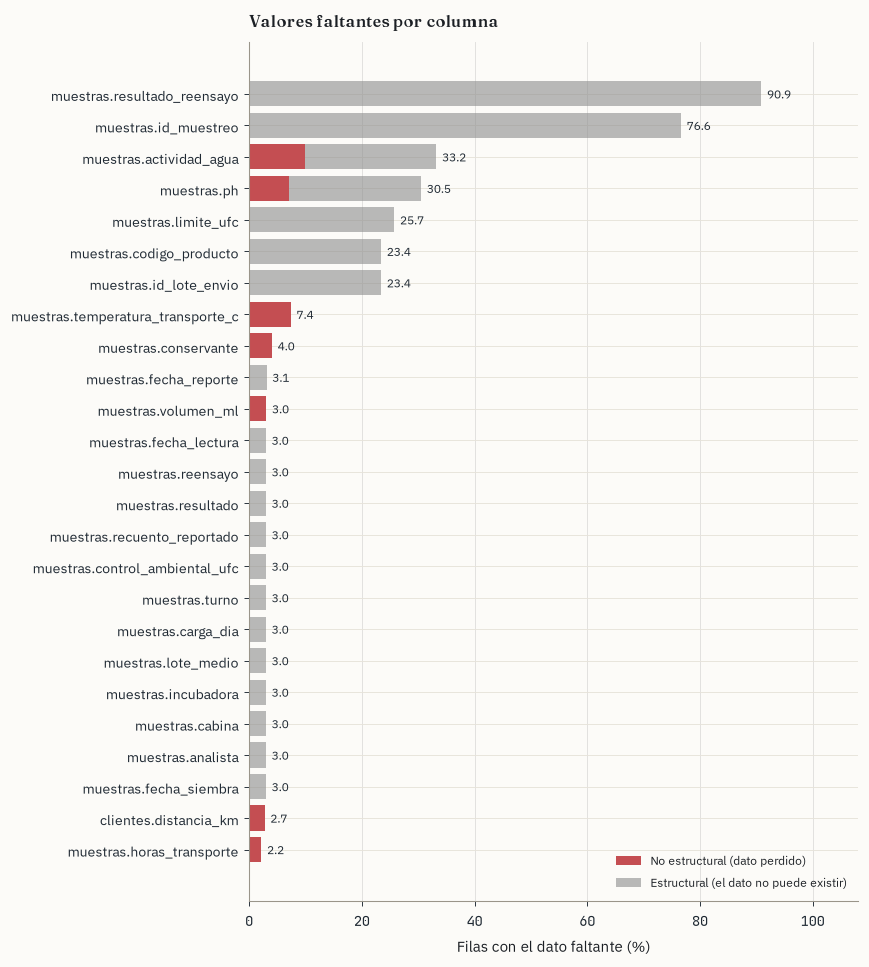

In [11]:
exploracion.faltantes(c).mostrar()

## 4. Volumen y estacionalidad

La primera pregunta es cuántas muestras van a llegar: volumen semanal por línea de negocio y
patrón dentro del año.

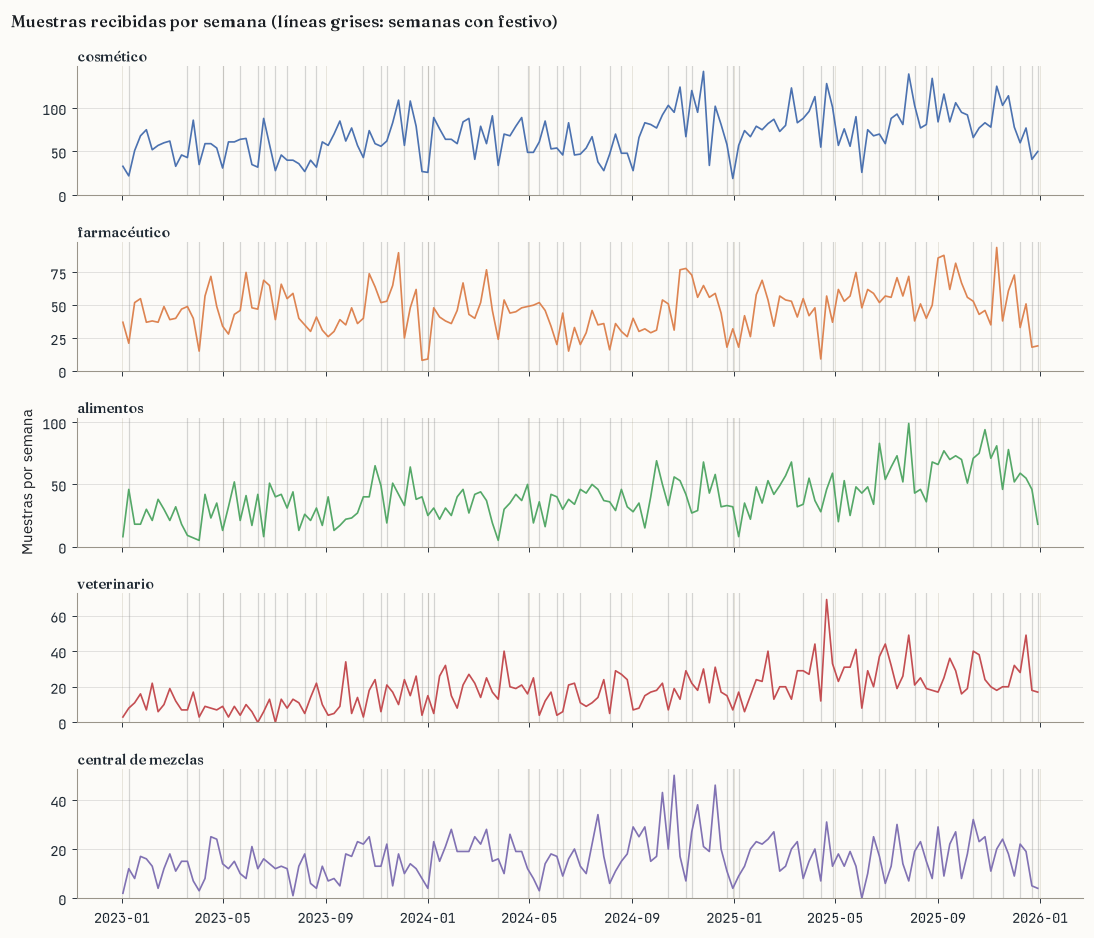

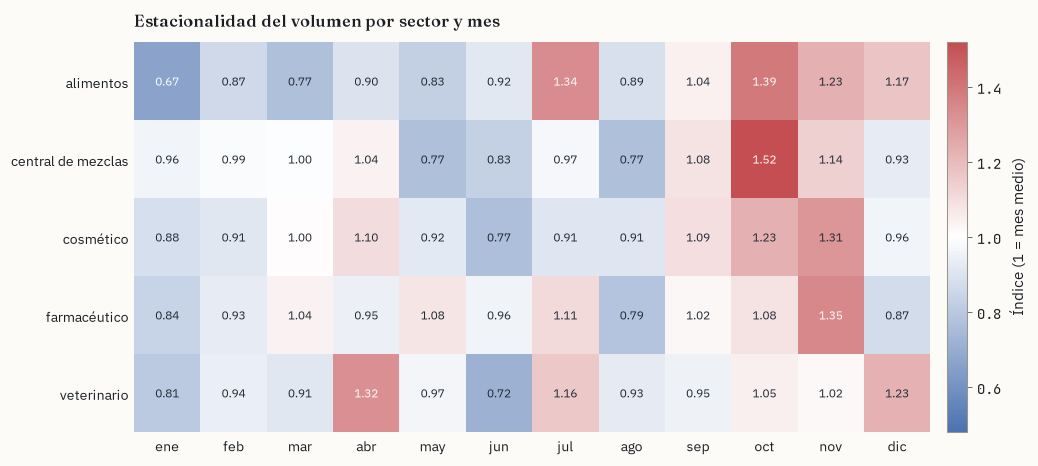

In [12]:
exploracion.volumen(c).mostrar()

## 5. Resultado no conforme

Qué tan frecuente es el resultado no conforme, cómo cambia por sector, matriz y ensayo, y cómo se
relaciona con las variables numéricas que ya se conocen cuando la muestra llega.

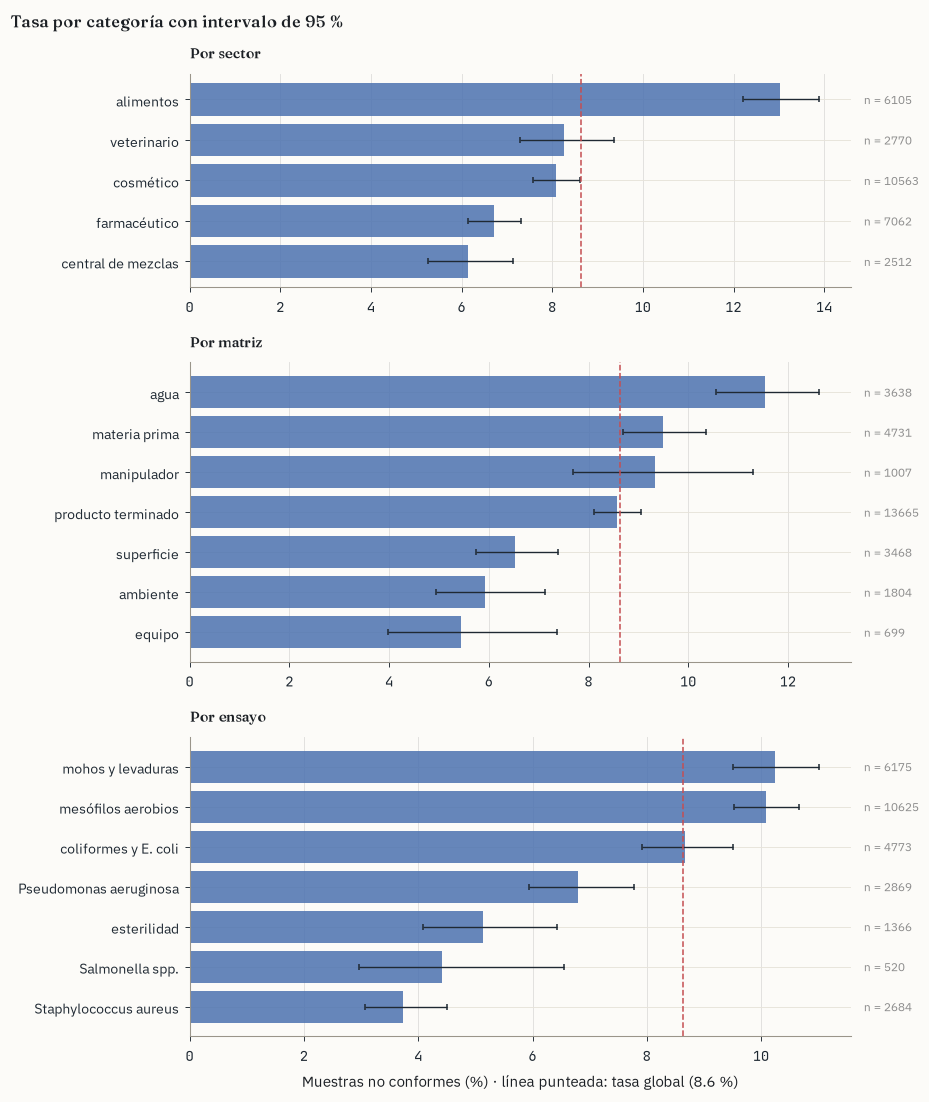

In [13]:
exploracion.tasa_no_conforme(c).mostrar()

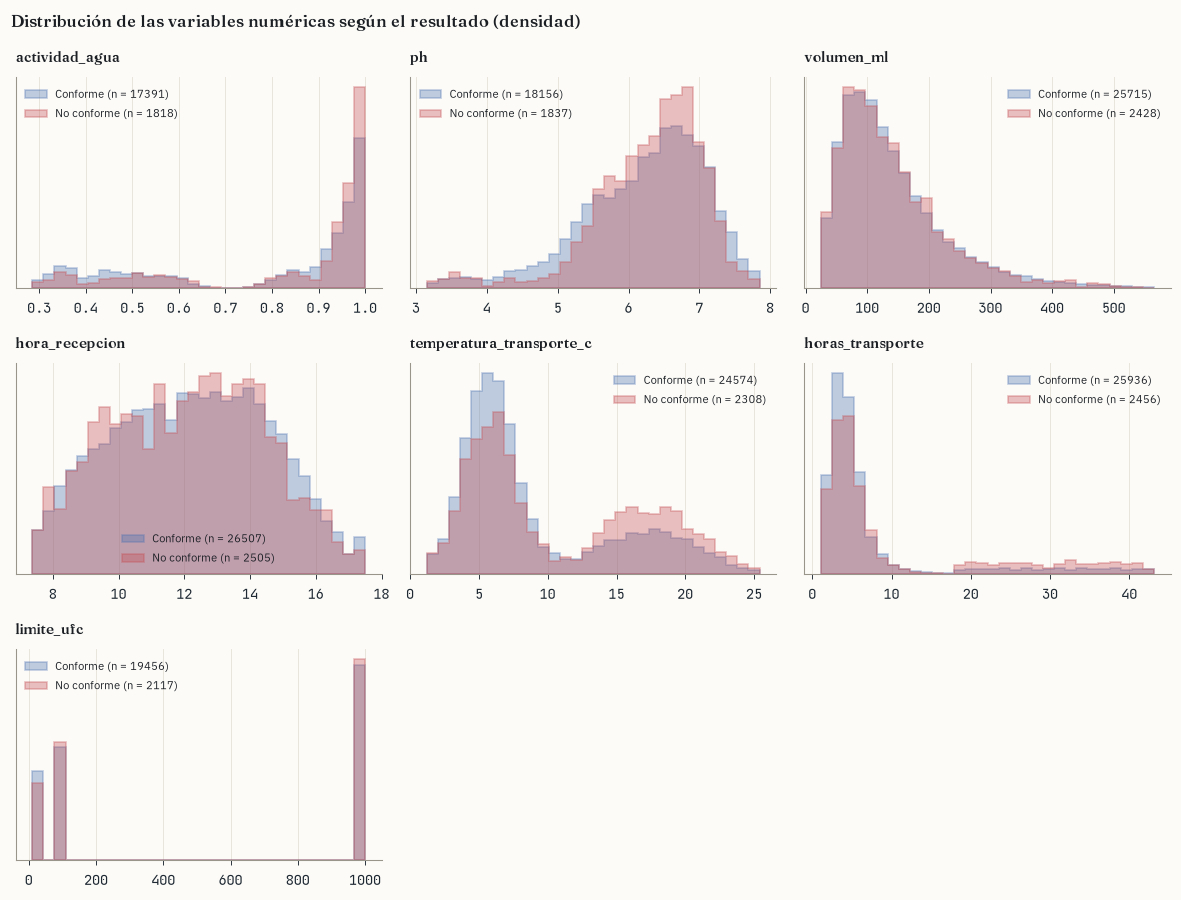

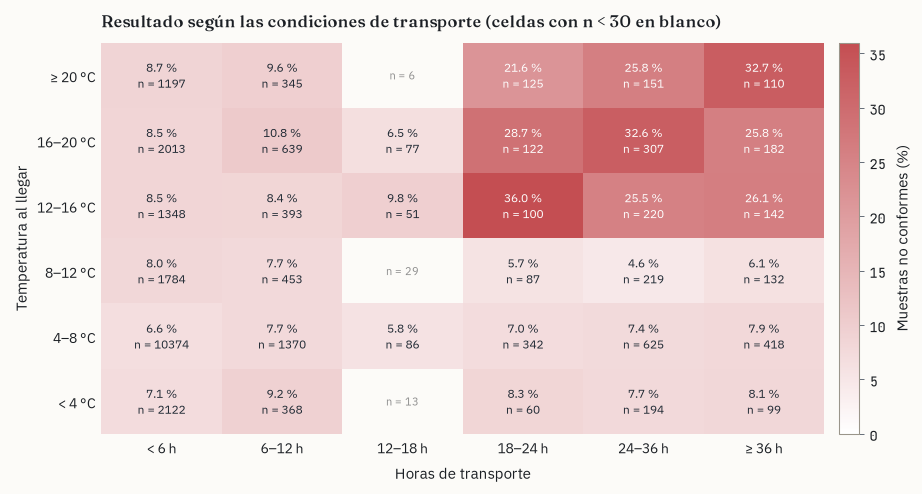

In [14]:
exploracion.distribuciones(c).mostrar()

## 6. Tiempos de entrega

El tiempo entre la recepción y el informe depende sobre todo de la incubación de cada ensayo.

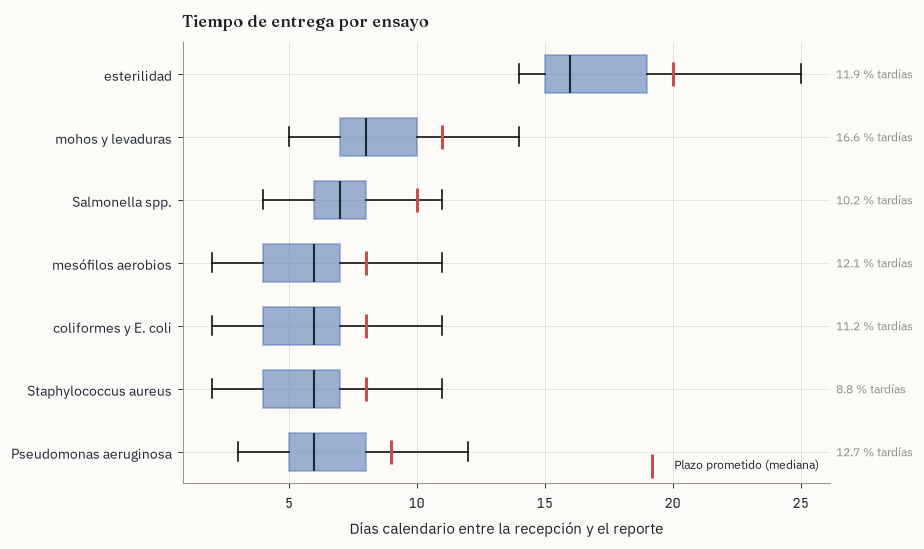

In [15]:
exploracion.entrega(c).mostrar()

## 7. Estabilidad en el tiempo

Un modelo ajustado con el pasado solo sirve si el futuro se le parece: ¿la tasa de no conformes es
estable mes a mes o deriva?

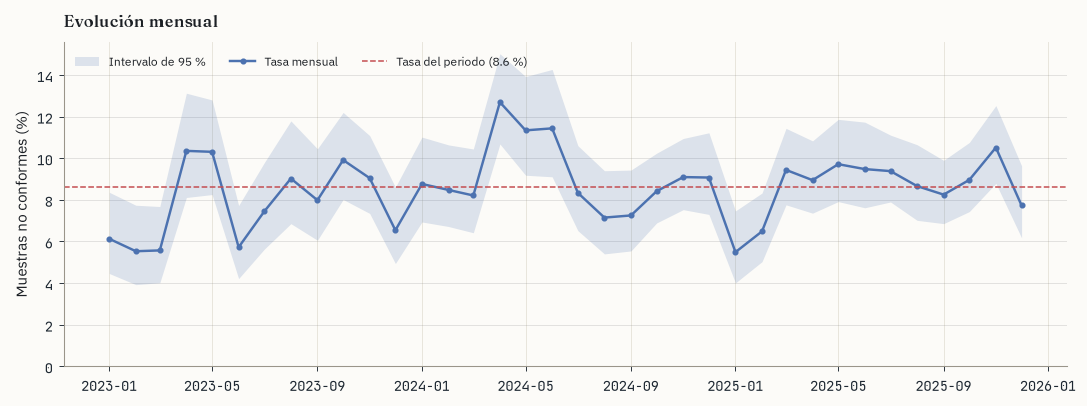

In [16]:
exploracion.estabilidad(c).mostrar()

## 8. Correlaciones entre variables numéricas

La correlación de Spearman (que no supone relaciones lineales) muestra qué variables son
redundantes y cuáles se asocian con los resultados.

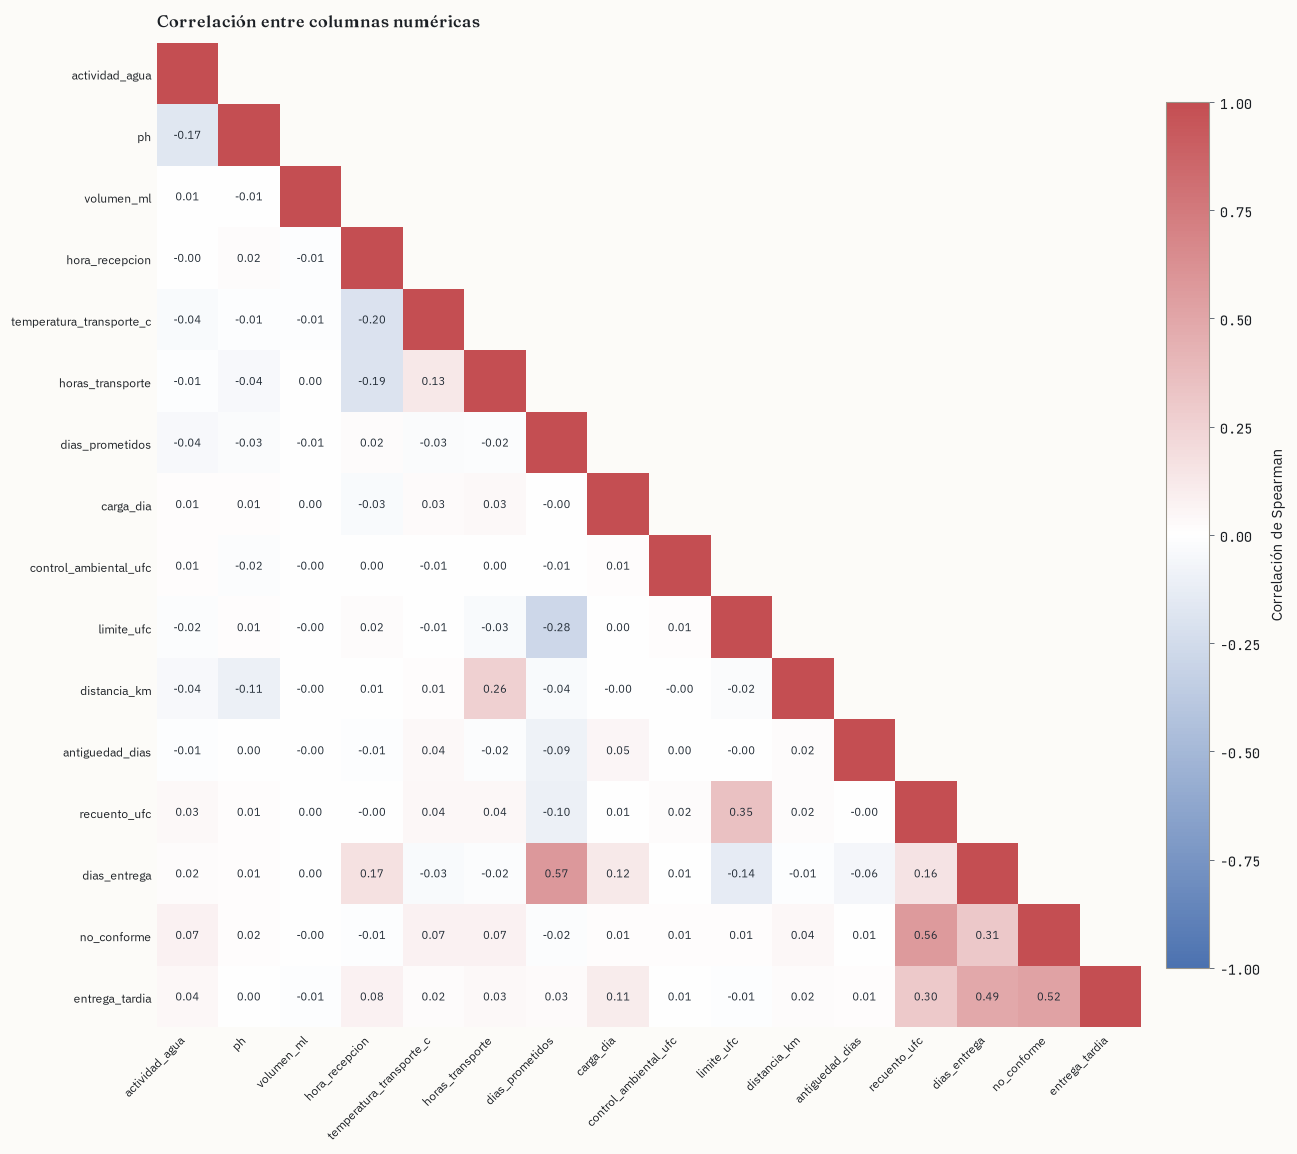

In [17]:
exploracion.correlaciones(c).mostrar()

## 9. Concentración del volumen por cliente

De cómo se reparte el volumen entre clientes depende cuánta historia tiene cada uno y qué tan
confiables son las variables construidas con su pasado.

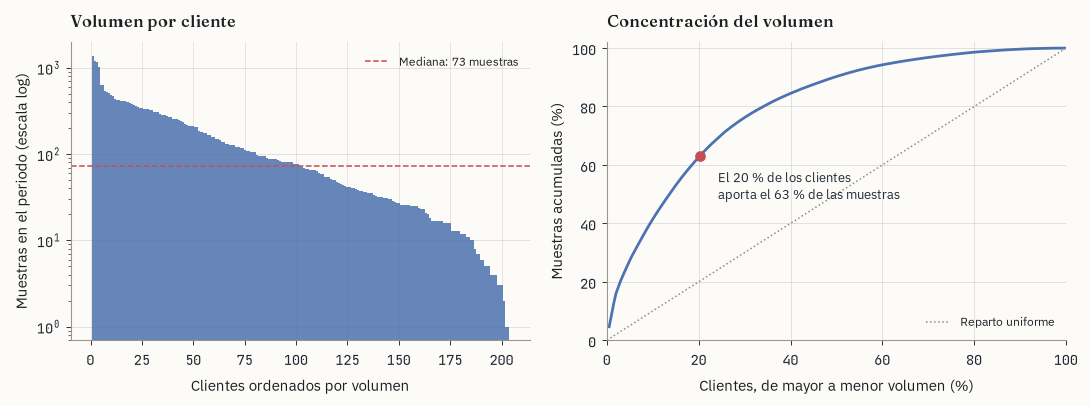

In [18]:
exploracion.concentracion(c).mostrar()

## 10. Qué implica todo esto para el modelado

In [19]:
exploracion.implicaciones(c).mostrar()

In [20]:
exploracion.terminar(c)

# 03 · Cribado de análisis: qué vale la pena modelar a fondo

Con la base del laboratorio se pueden plantear muchos análisis (prever volúmenes, anticipar
resultados, agrupar clientes), y estudiarlos todos a fondo no es viable. En esta etapa se los somete
a la misma prueba rápida y se decide, con una regla fijada de antemano, cuáles pasan al modelado
detallado de las etapas 04 a 06.

In [21]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import cribado

iniciar_etapa("03_cribado_analisis")
c = cribado.iniciar()
mostrar(c.encabezado)

## 1. El embudo de cribado

La idea viene del diseño de experimentos: probar de forma barata y uniforme muchas opciones y dar el
estudio costoso solo a las que pasan el filtro. Los cuatro pasos se escriben antes de ver resultados:

- **Catálogo:** cada candidato es una ficha con su unidad, objetivo, momento de predicción, métrica,
  línea base, decisión de negocio que apoya y un valor de negocio de 1 a 3.
- **Prueba rápida:** modelos sin afinar, solo con el entrenamiento y bloques temporales de ventana
  creciente.
- **Regla de selección:** umbrales fijos deciden quién es elegible y un puntaje (habilidad × valor
  de negocio) decide quién gana en cada tipo.
- **Modelado a fondo:** solo los ganadores pasan a las etapas 04, 05 y 06.

La **habilidad** compara candidatos de naturaleza distinta: en regresión es 1 − RMSE / RMSE de la
referencia (la fracción del error de la línea base que el modelo elimina), en clasificación es
2 · AUC − 1 (el coeficiente de Gini). En las series de tiempo la referencia es un pronóstico ingenuo
(el promedio de los últimos periodos), porque superar a la media global sería demasiado fácil. Las
fichas de tipo «bayes» no entrenan modelos: aplican el teorema de Bayes a los controles de calidad,
así que no se criban y pasan directo a la etapa 05.

In [22]:
cribado.catalogo_y_regla(c).mostrar()

Análisis,Título,Unidad,Objetivo,Momento,Métrica,Línea base,Decisión que apoya,Valor
volumen_semanal_linea,Volumen semanal de muestras por línea,semana × línea de negocio,muestras_semana,programacion,rmse,base_media_4,"Programar analistas, medios de cultivo e incubadoras de la semana siguiente.",3
carga_diaria,Carga diaria del laboratorio,día hábil,muestras_dia,programacion,rmse,base_media_5,Ajustar los turnos de recepción y siembra del día siguiente.,2
dias_entrega_recepcion,Días de entrega del informe,muestra aceptada,dias_entrega,recepcion,rmse,Dummy,Prometer al cliente una fecha de entrega realista al recibir la muestra.,2
recuento_log_recepcion,Recuento microbiano (log UFC),muestra aceptada con recuento,recuento_log,recepcion,rmse,Dummy,Anticipar las diluciones necesarias antes de sembrar.,1
visitas_mensuales_cliente,Visitas de muestreo por cliente y mes,cliente × mes,visitas_mes,maestro,rmse,base_media_3,Reservar técnicos de muestreo en planta para el mes siguiente.,1
Análisis,Título,Unidad,Objetivo,Momento,Métrica,Línea base,Decisión que apoya,Valor
no_conforme_recepcion,"Resultado no conforme, visto desde la recepción",muestra aceptada,no_conforme,recepcion,roc_auc,Dummy,Priorizar la siembra y avisar pronto al cliente de las muestras de mayor riesgo.,3
falso_positivo_lectura,Falso positivo entre los no conformes,resultado no conforme reensayado,falso_positivo,lectura,roc_auc,Dummy,Decidir qué resultados no conformes conviene reensayar antes de informar.,3
entrega_tardia_recepcion,Entrega tardía del informe,muestra aceptada,entrega_tardia,recepcion,roc_auc,Dummy,Reordenar la cola o avisar al cliente cuando el plazo prometido está en riesgo.,2
cliente_inactivo_trimestre,Cliente inactivo en el trimestre siguiente,cliente × trimestre,inactivo,maestro,roc_auc,Dummy,Indicar al área comercial qué clientes contactar antes de que dejen de enviar.,2


Análisis,Tipo,Unidad,Métrica,Línea base
volumen_semanal_linea,regresion,semana × línea de negocio,rmse,base_media_4
carga_diaria,regresion,día hábil,rmse,base_media_5
dias_entrega_recepcion,regresion,muestra aceptada,rmse,Dummy
recuento_log_recepcion,regresion,muestra aceptada con recuento,rmse,Dummy
visitas_mensuales_cliente,regresion,cliente × mes,rmse,base_media_3
no_conforme_recepcion,clasificacion,muestra aceptada,roc_auc,Dummy
falso_positivo_lectura,clasificacion,resultado no conforme reensayado,roc_auc,Dummy
entrega_tardia_recepcion,clasificacion,muestra aceptada,roc_auc,Dummy
cliente_inactivo_trimestre,clasificacion,cliente × trimestre,roc_auc,Dummy
rechazo_llegada,clasificacion,muestra recibida,roc_auc,Dummy


## 2. Tablas de modelado y auditoría de fugas

Cada ficha construye su tabla (una fila por unidad de análisis, con fecha, objetivo y variables) a
partir de las tablas limpias. La auditoría comprueba que cada variable se conozca antes o en el
momento de la predicción y que ningún identificador u objetivo entre como variable. Cada tabla se
parte por fecha y se guarda en dos archivos separados (desarrollo y prueba) junto con un JSON de
papeles de columnas; el bloque de prueba se guarda sin abrirlo y solo la etapa 07 puede leerlo.

In [23]:
cribado.tablas_modelado(c).mostrar()

Análisis,Tipo,Unidad,Momento,Variables,Filas de desarrollo,Filas de prueba,Hallazgos de fuga,Auditoría
volumen_semanal_linea,regresion,semana × línea de negocio,programacion,19,745,215,0,superada
carga_diaria,regresion,día hábil,programacion,16,714,203,0,superada
dias_entrega_recepcion,regresion,muestra aceptada,recepcion,46,28978,8652,0,superada
recuento_log_recepcion,regresion,muestra aceptada con recuento,recepcion,50,21573,6427,0,superada
visitas_mensuales_cliente,regresion,cliente × mes,maestro,21,2059,751,0,superada
no_conforme_recepcion,clasificacion,muestra aceptada,recepcion,51,29012,8657,0,superada
falso_positivo_lectura,clasificacion,resultado no conforme reensayado,lectura,56,2179,698,0,superada
entrega_tardia_recepcion,clasificacion,muestra aceptada,recepcion,46,28978,8652,0,superada
cliente_inactivo_trimestre,clasificacion,cliente × trimestre,maestro,23,1519,480,0,superada
rechazo_llegada,clasificacion,muestra recibida,llegada,46,29899,8947,0,superada


## 3. La prueba rápida

Cada candidato supervisado se evalúa con la línea base, un modelo lineal o logístico y un árbol poco
profundo sobre el grupo de variables ampliado; cada candidato de agrupamiento, con el estadístico de
Hopkins y la mejor silueta de K-means. Todo con las filas del entrenamiento.

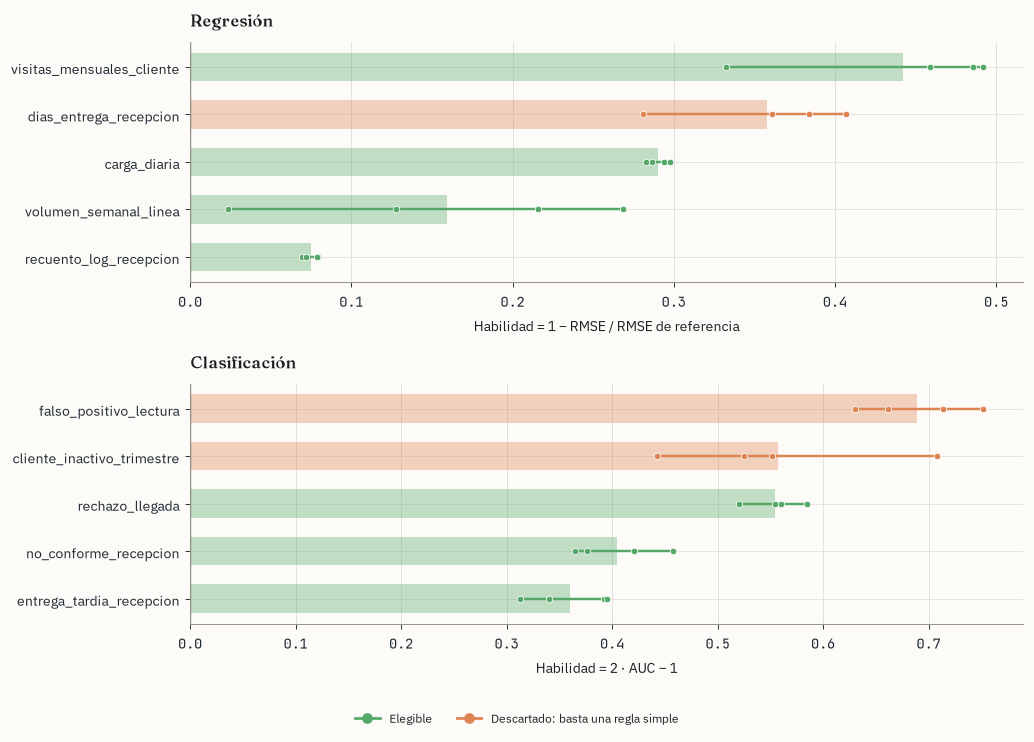

In [24]:
cribado.prueba_rapida(c).mostrar()

## 4. ¿Basta una regla simple?

Un modelo solo se justifica si combina información: en cada bloque se entrena un árbol que ve una
sola variable (la que más aporta) y, si su habilidad llega al umbral frente al mejor modelo rápido,
la recomendación es una regla operativa y no un modelo.

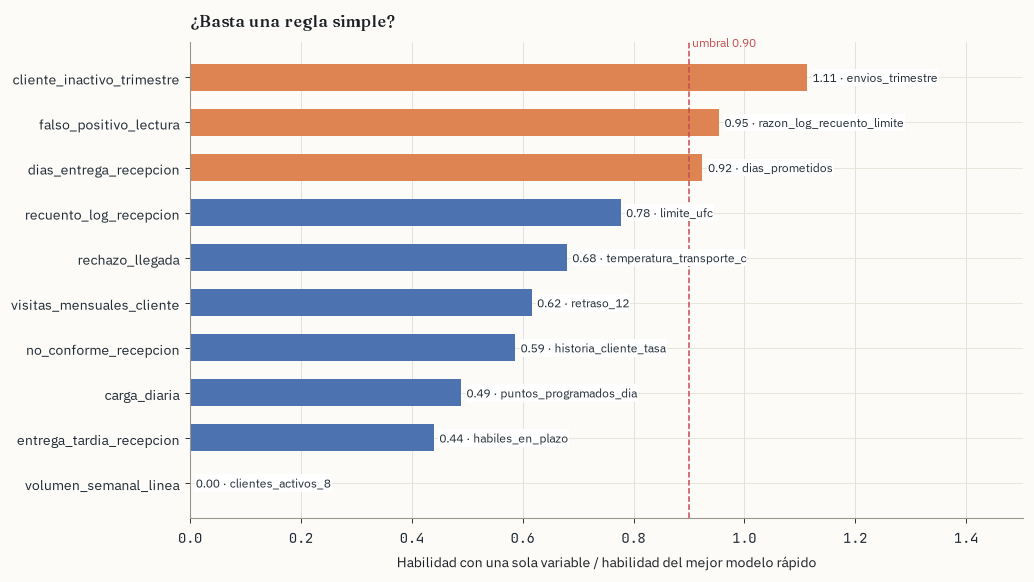

In [25]:
cribado.regla_simple(c).mostrar()

## 5. Candidatos de agrupamiento

Sin línea base que superar, la prueba pregunta si hay tendencia a formar grupos (Hopkins: cerca de
0.5 sin estructura, hacia 1 con grupos) y qué tan separados quedan los grupos de K-means (silueta).

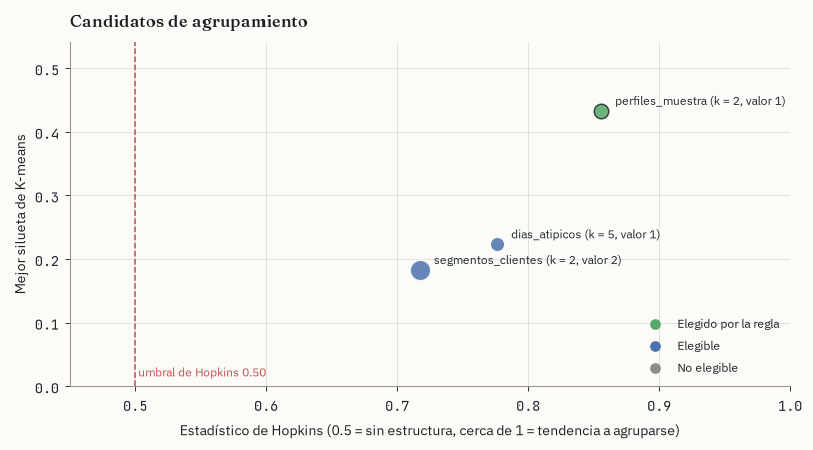

In [26]:
cribado.candidatos_agrupamiento(c).mostrar()

## 6. Selección

El embudo resume cuántos candidatos quedan en cada paso; las comparaciones muestran los mejores
puntajes de cada tipo, incluidos los no elegibles, para que se vea qué se dejó de lado y por qué.

In [27]:
cribado.seleccion(c).mostrar()

## 7. Consecuencias para las etapas siguientes

La selección no se toca después: las etapas 04 a 06 leen `artefactos/03_cribado.json`. La única
excepción, declarada aquí, es un análisis de agrupamiento complementario sobre los clientes.

In [28]:
cribado.consecuencias(c).mostrar()

In [29]:
cribado.terminar(c)

# 04 · Regresión: prever la carga de trabajo del laboratorio

El cribado eligió un análisis de regresión, y aquí se modela a fondo en tres niveles: los modelos
del curso con su configuración de partida (pasada didáctica), un cribado de los factores de la
tubería con un arreglo ortogonal de Taguchi y el afinamiento de hiperparámetros de lo que sobrevive,
evaluado una sola vez en validación antes de congelar el modelo.

In [30]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import regresion

iniciar_etapa("04_regresion")
c = regresion.iniciar()
mostrar(c.encabezado)

## 1. El problema y las referencias ingenuas

Un error de pocas muestras solo significa algo al lado de lo que el laboratorio ya consigue sin
modelo. Las referencias ingenuas (repetir lo de ayer, promediar la última semana) se evalúan en los
mismos tramos de validación de los bloques temporales que usarán los modelos.

In [31]:
regresion.planteamiento(c).mostrar()

In [32]:
regresion.referencias(c).mostrar()

Referencia,Bloque 1,Bloque 2,Bloque 3,Bloque 4
base_dia_anterior,21.43,22.68,29.32,28.17
base_media_5,15.67,16.46,22.51,20.39
Dummy (media),15.49,15.54,24.90,21.69


## 2. Pasada didáctica: los modelos del curso

Cada modelo usa el grupo de variables ampliado y el preprocesamiento por defecto (imputación por la
mediana y estandarización), sin afinar.

### 2.1 Regresión lineal simple

La variable con mayor correlación absoluta con el objetivo, en unidades originales, para que la
pendiente se lea en muestras por día.

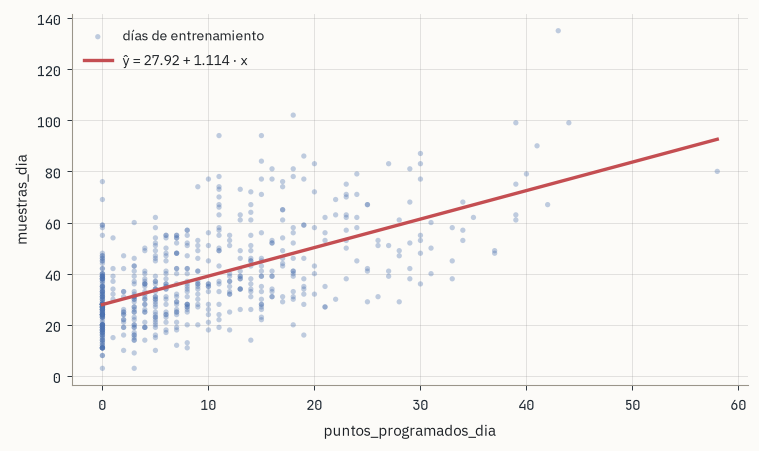

In [33]:
regresion.recta_simple(c).mostrar()

### 2.2 Árbol de regresión con poda por costo-complejidad

Se calcula la ruta de poda del árbol completo y se elige el `ccp_alpha` con menor RMSE medio en los
bloques: la complejidad la decide la validación, no una profundidad fijada a mano.

In [34]:
regresion.poda(c).mostrar()

ccp_alpha,Hojas,RMSE medio,Desv. RMSE
0.000,95,17.326,1.558
0.871,48,16.919,1.542
1.290,37,17.190,1.938
1.971,24,16.588,1.882
3.798,12,16.203,2.310
20.522,2,17.003,4.229


### 2.3 Regresión múltiple, KNN, árbol y perceptrón en los mismos bloques

Modelo,Tipo,MAE,RMSE,± RMSE,R²,± R²,Habilidad,Habilidad mínima
base_dia_anterior,referencia,20.165,25.399,3.926,-1.053,0.241,-0.357,-0.381
base_media_5,referencia,14.697,18.757,3.244,-0.111,0.078,0.000,0.000
Dummy (media),referencia,14.603,19.405,4.679,-0.167,0.120,-0.026,-0.106
Lineal simple (puntos_programados_dia),modelo,12.287,15.956,3.959,0.208,0.139,0.157,0.088
Lineal múltiple,modelo,10.446,13.310,2.262,0.440,0.047,0.290,0.283
KNN,modelo,11.498,15.416,3.409,0.259,0.067,0.183,0.140
Árbol podado,modelo,12.694,16.203,2.310,0.151,0.190,0.131,0.040
Perceptrón multicapa,modelo,10.900,14.308,2.807,0.350,0.131,0.238,0.171


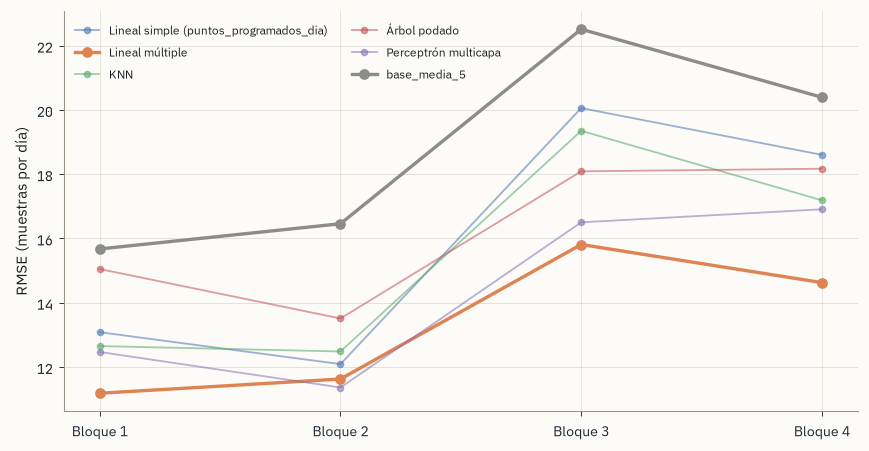

In [35]:
regresion.didactica(c).mostrar()

### 2.4 Qué dicen los coeficientes de la regresión múltiple

Con las variables estandarizadas, cada coeficiente es el cambio esperado en la carga cuando la
variable sube una desviación estándar y las demás quedan fijas.

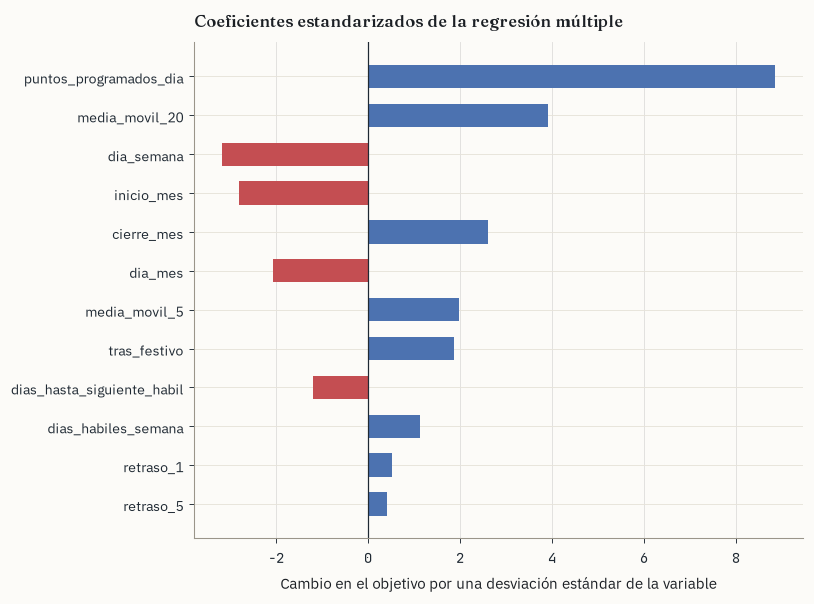

In [36]:
regresion.coeficientes(c).mostrar()

## 3. Nivel 2: cribado de la tubería con un arreglo L16 de Taguchi

Además del modelo, la tubería decide el escalado, el grupo de variables, si el objetivo va en
logaritmo, si se seleccionan variables y cómo se codifican las discretas. Probar todo exige
4 × 2⁵ = 128 corridas; un arreglo ortogonal L16 estima los efectos principales de los seis factores
con 16, porque cada nivel aparece el mismo número de veces frente a los niveles de los demás. El
precio es que algunas interacciones quedan confundidas con efectos principales: la tabla de
confusiones dice exactamente cuáles.

La respuesta es el RMSE de cada bloque, resumido con la razón señal/ruido «menor es mejor»,
S/N = −10 · log10(media de RMSE²), que castiga a la vez un error alto y un error inestable.

In [37]:
regresion.diseno(c).mostrar()

Corrida,modelo,escalado,grupo,objetivo_log,seleccion,codificacion
1,knn,estandar,base,no,ninguna,ordinal
2,knn,estandar,ampliado,sí,8,one_hot
3,knn,minmax,base,no,8,one_hot
4,knn,minmax,ampliado,sí,ninguna,ordinal
5,lineal,estandar,base,sí,ninguna,one_hot
6,lineal,estandar,ampliado,no,8,ordinal
7,lineal,minmax,base,sí,8,ordinal
8,lineal,minmax,ampliado,no,ninguna,one_hot
9,arbol,estandar,base,sí,8,ordinal
10,arbol,estandar,ampliado,no,ninguna,one_hot


Factor 1,Factor 2,Columnas de la interacción,Confundida con
modelo,escalado,"ac, bc, abc",libre
modelo,grupo,"ad, bd, abd",objetivo_log
modelo,objetivo_log,"d, ad, bd",grupo
modelo,seleccion,"cd, bcd, abcd",codificacion
modelo,codificacion,"cd, acd, abcd",seleccion
escalado,grupo,cd,libre
escalado,objetivo_log,abcd,libre
escalado,seleccion,ad,libre
escalado,codificacion,bd,libre
grupo,objetivo_log,A,modelo


Con las 16 corridas se calculan los efectos principales (la S/N media en cada nivel), la tabla de
respuesta (delta entre el mejor y el peor nivel) y el óptimo que predice el modelo aditivo.

Corrida,modelo,escalado,grupo,objetivo_log,seleccion,codificacion,bloque_1,bloque_2,bloque_3,bloque_4,media,desv,sn,segundos
1,knn,estandar,base,no,ninguna,ordinal,12.29,14.35,21.60,18.17,16.60,4.13,-24.60,0.04
2,knn,estandar,ampliado,sí,8,one_hot,12.91,12.09,20.66,16.59,15.56,3.92,-24.04,0.06
3,knn,minmax,base,no,8,one_hot,12.01,14.73,21.43,16.85,16.26,3.98,-24.41,0.04
4,knn,minmax,ampliado,sí,ninguna,ordinal,13.73,14.09,21.33,20.30,17.36,4.01,-24.96,0.05
5,lineal,estandar,base,sí,ninguna,one_hot,11.92,14.05,21.43,17.83,16.31,4.20,-24.46,0.03
6,lineal,estandar,ampliado,no,8,ordinal,11.47,11.48,16.25,14.64,13.46,2.38,-22.68,0.04
7,lineal,minmax,base,sí,8,ordinal,12.30,14.16,21.13,17.56,16.28,3.89,-24.42,0.03
8,lineal,minmax,ampliado,no,ninguna,one_hot,11.25,11.61,15.96,14.71,13.38,2.32,-22.63,0.04
9,arbol,estandar,base,sí,8,ordinal,13.47,15.21,23.23,18.71,17.65,4.31,-25.13,0.04
10,arbol,estandar,ampliado,no,ninguna,one_hot,13.00,13.27,19.19,19.02,16.12,3.45,-24.29,0.04


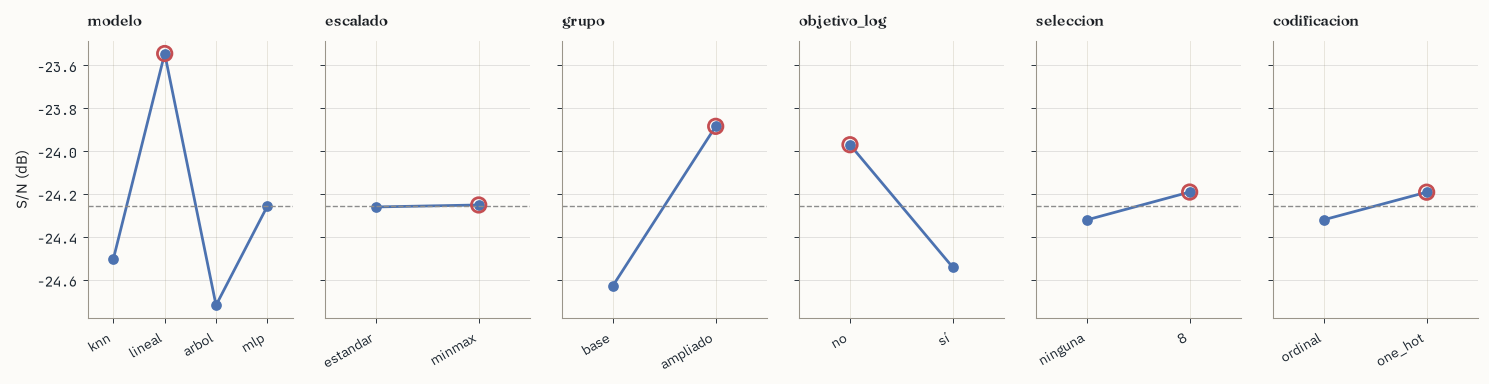

Factor,Mejor nivel,S/N mejor,Peor nivel,S/N peor,Delta,Rango
modelo,lineal,-23.55,arbol,-24.72,1.17,1
grupo,ampliado,-23.89,base,-24.63,0.74,2
objetivo_log,no,-23.97,sí,-24.54,0.57,3
seleccion,8,-24.19,ninguna,-24.32,0.13,4
codificacion,one_hot,-24.19,ordinal,-24.32,0.13,5
escalado,minmax,-24.25,estandar,-24.26,0.01,6


In [38]:
regresion.corridas_l16(c).mostrar()

### Corrida de confirmación y factorial completo

El óptimo predicho supone efectos que se suman sin interactuar: se ejecuta y se compara la S/N
observada con la predicha, con una tolerancia de dos veces el error residual del modelo aditivo.
Después, si el tiempo estimado (el del L16 por 128 / 16) no pasa de un minuto, se ejecuta el
factorial completo para comprobar el atajo de Taguchi.

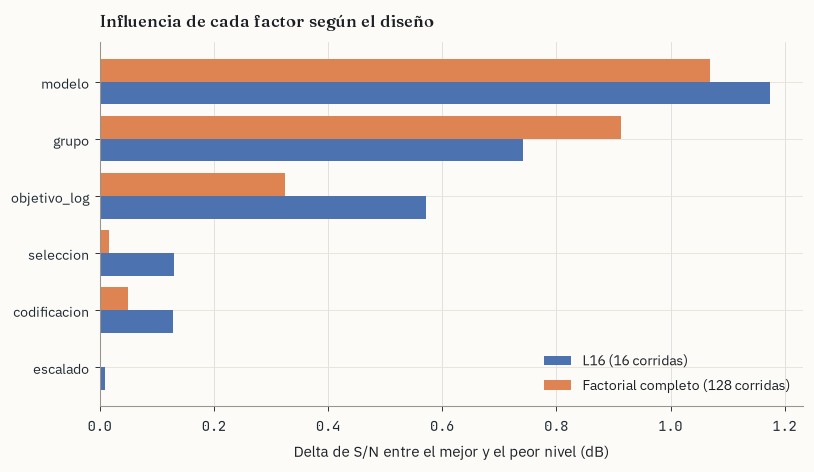

In [39]:
regresion.confirmacion(c).mostrar()

## 4. Nivel 3: afinamiento de hiperparámetros

Pasa la configuración de mayor S/N observada (la confirmación o la mejor del L16) y, para no
apostar a una sola familia, la segunda mejor familia de modelos con los demás factores iguales. Las
rejillas se recorren con `GridSearchCV` sobre los mismos bloques temporales.

In [40]:
regresion.afinamiento(c).mostrar()

### Evaluación única en validación

La regla se fija antes de mirar: gana el menor RMSE de validación y, si la diferencia es menor que
el 1 %, el modelo más sencillo (lineal, árbol, KNN, perceptrón).

In [41]:
regresion.evaluacion_validacion(c).mostrar()

Predictor,MAE,RMSE,R2,Habilidad,RMSE inf.,RMSE sup.,Habilidad inf.,Habilidad sup.
Regresión lineal,11.030,14.591,0.367,0.249,12.229,17.211,0.154,0.343
Perceptrón multicapa,11.730,15.513,0.285,0.201,13.061,18.458,0.102,0.292
base_dia_anterior,20.688,25.768,-0.973,-0.327,—,—,—,—
base_media_5,15.355,19.423,-0.121,0.000,—,—,—,—
Dummy (media),18.436,24.121,-0.729,-0.242,—,—,—,—


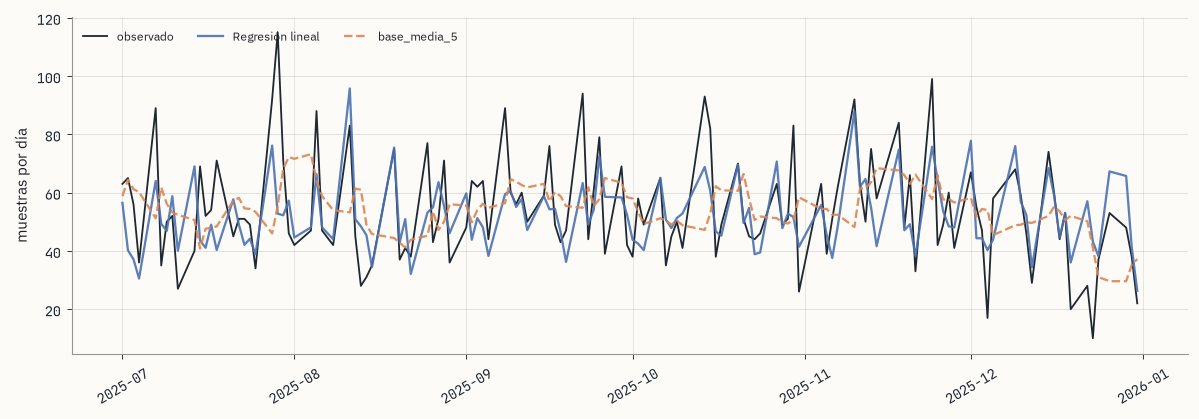

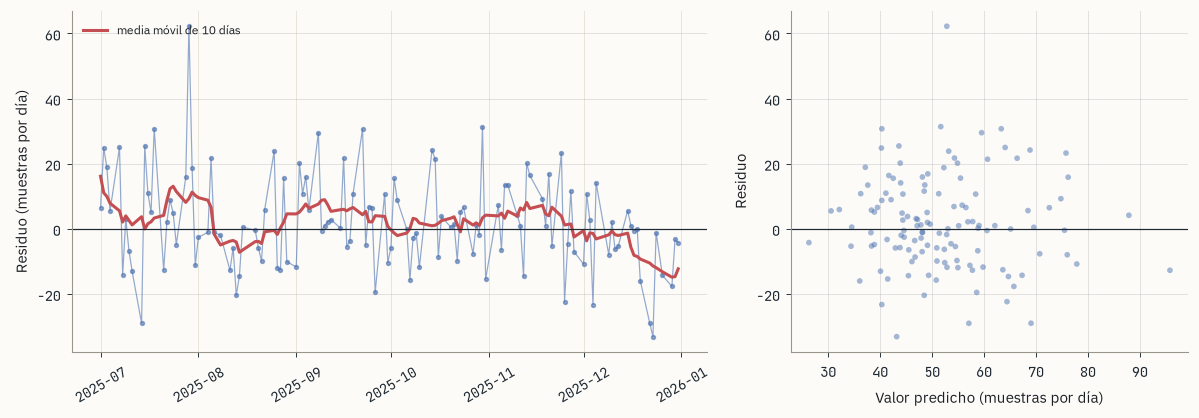

In [42]:
regresion.diagnostico(c).mostrar()

## 5. Congelamiento del modelo

Hiperparámetros y configuración quedan fijos; el modelo se reajusta con entrenamiento y validación,
porque los días recientes describen mejor el nivel actual de la serie. La etapa 07 lo evaluará una
sola vez en la prueba.

In [43]:
regresion.congelar(c).mostrar()

## 6. Qué significa en la operación

El error se traduce a muestras por día y a la frecuencia con que la predicción se aleja más de una
tolerancia práctica, fijada en el 20 % de la carga diaria media de validación.

In [44]:
regresion.operacion(c).mostrar()

In [45]:
regresion.terminar(c)

# 05 · Clasificación y Bayes: qué muestras vigilar y cuánto creerle a un positivo

Dos partes que se apoyan una en la otra. En la parte A se modela, con los mismos tres niveles de la
etapa 04, la probabilidad de que una muestra aceptada termine no conforme, vista desde la recepción,
y se fija un umbral de alerta por costo. En la parte B se responde la pregunta original del
laboratorio, la probabilidad de que un positivo sea falso, combinando la fiabilidad de cada ensayo
(sus controles de calidad) con el riesgo previo de cada muestra que entrega el clasificador.

In [46]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import clasificacion

iniciar_etapa("05_clasificacion_bayes")
c = clasificacion.iniciar()
mostrar(c.encabezado)

## Parte A · Clasificación

## 1. El problema, la decisión y sus costos

El costo de cada error se fija antes de ver resultados, porque de él depende el umbral y no al revés.
Con una clase positiva tan escasa la exactitud engaña, de forma que se usan el ROC-AUC (probabilidad
de que una no conforme reciba más riesgo que una conforme), la precisión media (área bajo la curva
precisión-recall, cuya referencia es la prevalencia) y el Brier (error cuadrático de la probabilidad,
que premia la calibración), frente a un `Dummy` que predice la proporción del entrenamiento.

In [47]:
clasificacion.planteamiento(c).mostrar()

## 2. Pasada didáctica: los modelos del curso

Cada modelo usa el grupo ampliado y el preprocesamiento por defecto (imputación por la mediana,
estandarización y one-hot), sin afinar, en los mismos bloques temporales.

### 2.1 Árbol de clasificación con poda por costo-complejidad

In [48]:
clasificacion.poda(c).mostrar()

ccp_alpha,Hojas,ROC-AUC medio,Desv. ROC-AUC
0.000000,546,0.610,0.015
0.000038,298,0.620,0.022
0.000053,227,0.620,0.028
0.000072,148,0.620,0.034
0.000122,52,0.639,0.011
0.001655,2,0.556,0.031


### 2.2 KNN, regresión logística, árbol podado y perceptrón, con sus curvas ROC

Modelo,ROC-AUC,± ROC-AUC,Precisión media,± Precisión media,Brier,± Brier,Habilidad (2·AUC − 1)
Dummy (proporción),0.5000,0.0000,0.0892,0.0131,0.0813,0.0110,0.0000
KNN,0.6337,0.0243,0.1647,0.0181,0.0808,0.0106,0.2673
Regresión logística,0.7025,0.0214,0.2539,0.0194,0.0754,0.0096,0.4049
Árbol podado,0.6386,0.0114,0.1775,0.0074,0.0849,0.0101,0.2771
Perceptrón multicapa,0.6921,0.0210,0.2354,0.0323,0.0761,0.0096,0.3843


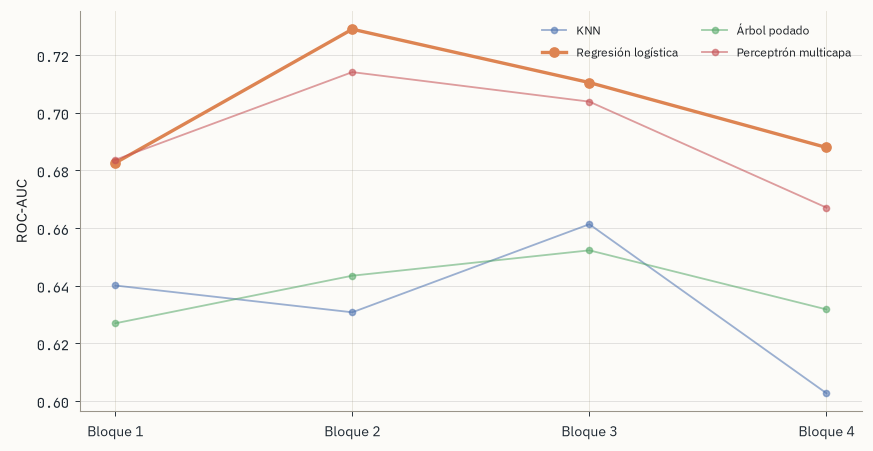

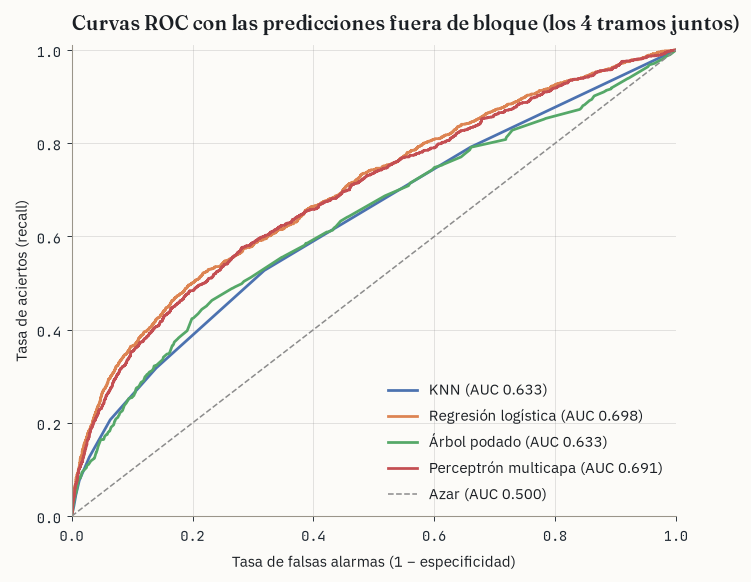

In [49]:
clasificacion.didactica(c).mostrar()

### 2.3 Qué dice la regresión logística

Con las numéricas estandarizadas, cada coeficiente es el cambio en el logaritmo de las odds de no
conformidad cuando la variable sube una desviación estándar, y su exponencial es la razón de odds
(1.5 significa odds un 50 % mayores).

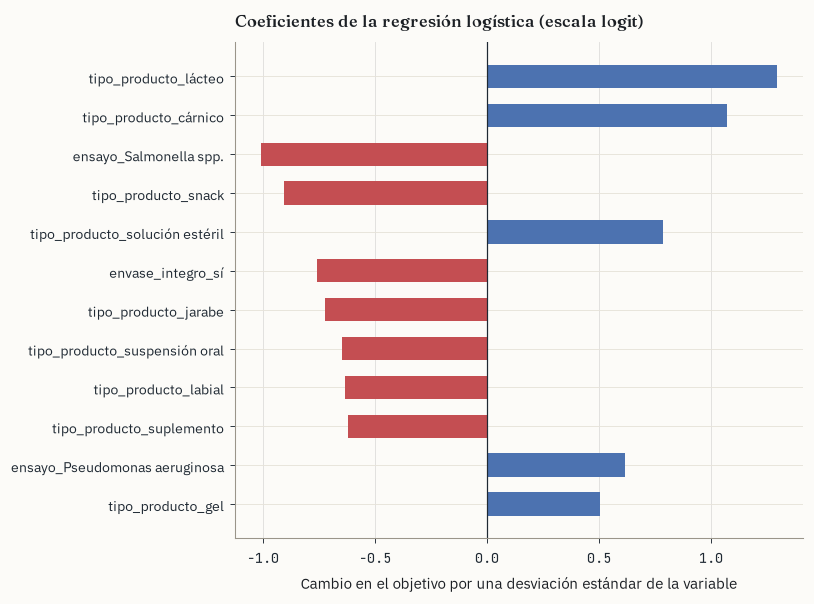

Variable,Coeficiente,Razón de odds
tipo_producto_lácteo,1.295,3.651
tipo_producto_cárnico,1.072,2.921
ensayo_Salmonella spp.,-1.011,0.364
tipo_producto_snack,-0.904,0.405
tipo_producto_solución estéril,0.783,2.188
envase_integro_sí,-0.758,0.468
tipo_producto_jarabe,-0.725,0.484
tipo_producto_suspensión oral,-0.648,0.523


In [50]:
clasificacion.logistica(c).mostrar()

### 2.4 Las reglas del árbol podado

Cada hoja es una conjunción de condiciones con la fracción de no conformes de las muestras de
entrenamiento que caen en ella; se muestran las de mayor riesgo.

In [51]:
clasificacion.reglas_arbol(c).mostrar()

Regla,Filas,Fracción de positivos
historia_producto_tasa > 0.1178 y temperatura_por_horas ≤ 298.8 y historia_producto_tasa > 0.185 y es_cuantitativo > 0.5 y ph ≤ 6.815 y temperatura_por_horas ≤ 26.31 y temperatura_por_horas > 22.47,22,0.773
historia_producto_tasa > 0.1178 y temperatura_por_horas > 298.8 y historia_producto_tasa > 0.1926,45,0.756
historia_producto_tasa > 0.1178 y temperatura_por_horas > 298.8 y historia_producto_tasa ≤ 0.1926 y historia_cliente_n_90 > 32 y volumen_ml ≤ 111,36,0.722
historia_producto_tasa > 0.1178 y temperatura_por_horas ≤ 298.8 y historia_producto_tasa > 0.185 y es_cuantitativo > 0.5 y ph ≤ 6.815 y temperatura_por_horas > 26.31 y tamano_lote > 4.5 y antiguedad_dias ≤ 1320,20,0.700
historia_producto_tasa ≤ 0.1178 y temperatura_por_horas > 293.2 y historia_producto_tasa > 0.0813 y actividad_agua > 0.9445 y horas_transporte ≤ 24.25,41,0.659
historia_producto_tasa > 0.1178 y temperatura_por_horas ≤ 298.8 y historia_producto_tasa > 0.185 y es_cuantitativo > 0.5 y ph ≤ 6.815 y temperatura_por_horas ≤ 26.31 y temperatura_por_horas ≤ 22.47 y hora_recepcion > 13.57,20,0.650


## 3. Nivel 2: cribado de la tubería con un arreglo L16 de Taguchi

Los factores son el modelo, el escalado, el grupo de variables, el tratamiento del desbalance
(sobremuestreo de la clase minoritaria, solo al ajustar), la selección de variables y la
codificación; las 128 combinaciones se reducen a 16 con la misma asignación de columnas de la etapa
04. La respuesta es el ROC-AUC de cada bloque, resumido con la S/N «mayor es mejor»,
S/N = −10 · log10(media de 1 / AUC²).

In [52]:
clasificacion.diseno(c).mostrar()

Corrida,modelo,escalado,grupo,desbalance,seleccion,codificacion
1,knn,estandar,base,ninguna,ninguna,one_hot
2,knn,estandar,ampliado,sobremuestreo,26,ordinal
3,knn,minmax,base,ninguna,26,ordinal
4,knn,minmax,ampliado,sobremuestreo,ninguna,one_hot
5,logistica,estandar,base,sobremuestreo,ninguna,ordinal
6,logistica,estandar,ampliado,ninguna,26,one_hot
7,logistica,minmax,base,sobremuestreo,26,one_hot
8,logistica,minmax,ampliado,ninguna,ninguna,ordinal
9,arbol,estandar,base,sobremuestreo,26,one_hot
10,arbol,estandar,ampliado,ninguna,ninguna,ordinal


Factor 1,Factor 2,Columnas de la interacción,Confundida con
modelo,escalado,"ac, bc, abc",libre
modelo,grupo,"ad, bd, abd",desbalance
modelo,desbalance,"d, ad, bd",grupo
modelo,seleccion,"cd, bcd, abcd",codificacion
modelo,codificacion,"cd, acd, abcd",seleccion
escalado,grupo,cd,libre
escalado,desbalance,abcd,libre
escalado,seleccion,ad,libre
escalado,codificacion,bd,libre
grupo,desbalance,A,modelo


Corrida,modelo,escalado,grupo,desbalance,seleccion,codificacion,bloque_1,bloque_2,bloque_3,bloque_4,media,desv,sn,segundos
1,knn,estandar,base,ninguna,ninguna,one_hot,0.626,0.604,0.637,0.629,0.624,0.014,-4.10,1.2
2,knn,estandar,ampliado,sobremuestreo,26,ordinal,0.603,0.637,0.643,0.640,0.631,0.019,-4.01,1.6
3,knn,minmax,base,ninguna,26,ordinal,0.616,0.617,0.626,0.654,0.628,0.018,-4.05,1.1
4,knn,minmax,ampliado,sobremuestreo,ninguna,one_hot,0.603,0.614,0.632,0.608,0.614,0.013,-4.24,1.5
5,logistica,estandar,base,sobremuestreo,ninguna,ordinal,0.661,0.711,0.685,0.663,0.680,0.023,-3.36,1.5
6,logistica,estandar,ampliado,ninguna,26,one_hot,0.681,0.727,0.697,0.669,0.693,0.025,-3.19,1.0
7,logistica,minmax,base,sobremuestreo,26,one_hot,0.670,0.710,0.690,0.651,0.680,0.026,-3.36,0.9
8,logistica,minmax,ampliado,ninguna,ninguna,ordinal,0.680,0.726,0.701,0.672,0.695,0.024,-3.17,1.4
9,arbol,estandar,base,sobremuestreo,26,one_hot,0.618,0.676,0.639,0.657,0.647,0.024,-3.79,1.0
10,arbol,estandar,ampliado,ninguna,ninguna,ordinal,0.658,0.685,0.669,0.635,0.662,0.021,-3.59,1.3


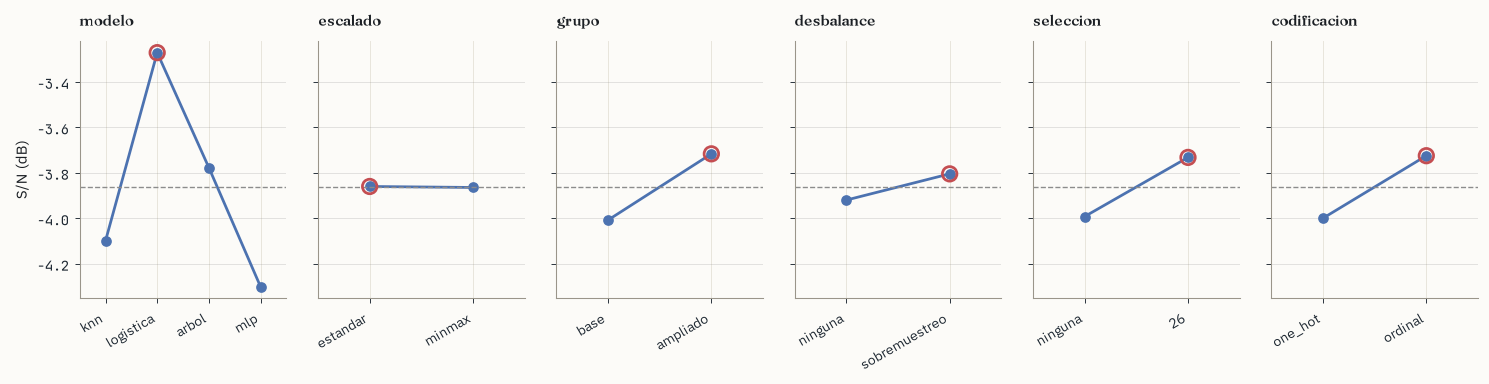

Factor,Mejor nivel,S/N mejor,Peor nivel,S/N peor,Delta,Rango
modelo,logistica,-3.272,mlp,-4.302,1.030,1
grupo,ampliado,-3.717,base,-4.008,0.292,2
codificacion,ordinal,-3.725,one_hot,-4.000,0.275,3
seleccion,26,-3.733,ninguna,-3.993,0.260,4
desbalance,sobremuestreo,-3.805,ninguna,-3.920,0.115,5
escalado,estandar,-3.860,minmax,-3.865,0.004,6


In [53]:
clasificacion.corridas_l16(c).mostrar()

### Comprobación dirigida: modelo × sobremuestreo

El sobremuestreo no afecta igual a todos los modelos: en el perceptrón con parada temprana, copias
de un mismo no conforme caen a la vez en su entrenamiento y en su validación interna; y en todos, al
igualar las clases, las probabilidades dejan de estar calibradas. Para separar esto de las
confusiones del L16, cada modelo didáctico se repite con sobremuestreo.

In [54]:
clasificacion.sobremuestreo(c).mostrar()

Modelo,AUC sin,AUC con,Δ AUC,Brier sin,Brier con,Prob. media sin,Prob. media con
KNN,0.634,0.615,-0.019,0.081,0.257,0.088,0.383
Regresión logística,0.702,0.699,-0.003,0.075,0.227,0.095,0.451
Árbol podado,0.639,0.597,-0.041,0.085,0.200,0.098,0.243
Perceptrón multicapa,0.692,0.612,-0.080,0.076,0.176,0.097,0.193


### Corrida de confirmación y factorial completo

In [55]:
clasificacion.confirmacion(c).mostrar()

## 4. Nivel 3: afinamiento de hiperparámetros

Como en la etapa 04: la configuración de mayor S/N observada y la segunda mejor familia de modelos,
con `GridSearchCV` en los mismos bloques y el ROC-AUC como métrica.

In [56]:
clasificacion.afinamiento(c).mostrar()

### Evaluación única en validación

Regla fijada antes de mirar: gana el mayor ROC-AUC de validación y, si la diferencia es menor que
0.005, el más sencillo (regresión logística, árbol, KNN, perceptrón).

In [57]:
clasificacion.evaluacion_validacion(c).mostrar()

Candidato,ROC-AUC,AUC inf.,AUC sup.,Precisión media,Brier
Regresión logística,0.7243,0.7008,0.7482,0.2582,0.2269
Árbol de decisión,0.6969,0.6721,0.7201,0.2035,0.2332
Dummy (proporción),0.5000,—,—,0.0893,0.0814


## 5. Calibración

El umbral teórico y la parte B suponen que una probabilidad de 0.2 significa que unas veinte de
cada cien muestras así salen no conformes. La versión calibrada usa `CalibratedClassifierCV` con el
método sigmoide (Platt, dos parámetros, adecuado con pocos no conformes por tramo) y los mismos
bloques temporales como `cv`. Regla: se usa la calibrada si la tubería sobremuestrea o si su Brier de
validación es menor.

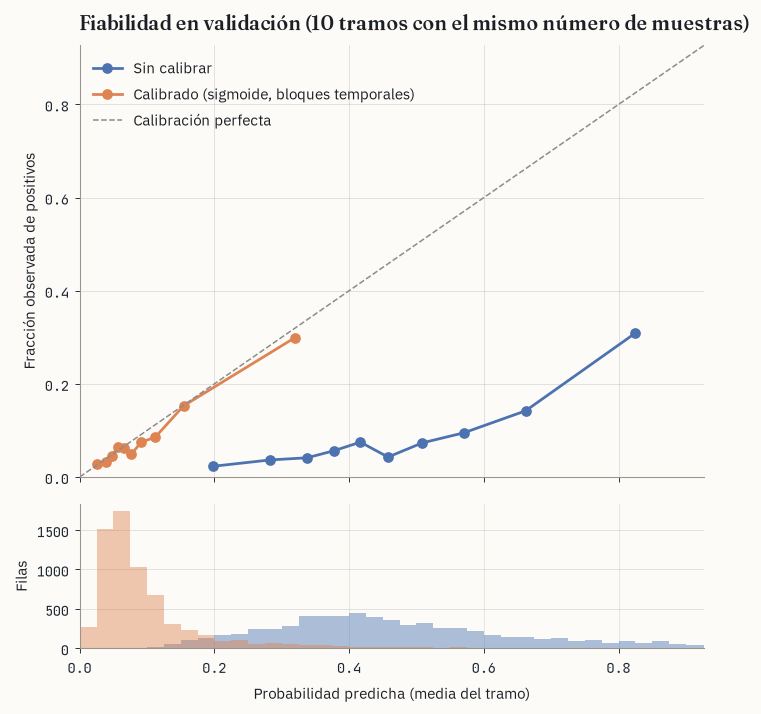

In [58]:
clasificacion.calibracion(c).mostrar()

## 6. Umbral por costo en validación

Se recorren umbrales de 0.02 a 0.50 (más el teórico) y se elige el de menor costo, desempatando
hacia el más alto. Al lado del costo van siempre la precisión, el recall y las alertas por semana,
que es la carga real que recibe el laboratorio.

Umbral,Alertas,Alertas por semana,Precisión,Recall,FP,FN,Costo
0.020,6446,238.7,0.090,0.990,5867,6,5897
0.040,5511,204.1,0.101,0.949,4956,30,5106
0.060,3988,147.7,0.120,0.819,3509,106,4039
0.080,2778,102.9,0.148,0.704,2366,173,3231
0.100,1994,73.9,0.177,0.603,1641,232,2801
0.120,1430,53.0,0.215,0.525,1123,278,2513
0.140,1114,41.3,0.246,0.468,840,311,2395
0.160,898,33.3,0.266,0.409,659,346,2389
0.167,843,31.2,0.275,0.397,611,353,2376
0.180,732,27.1,0.288,0.361,521,374,2391


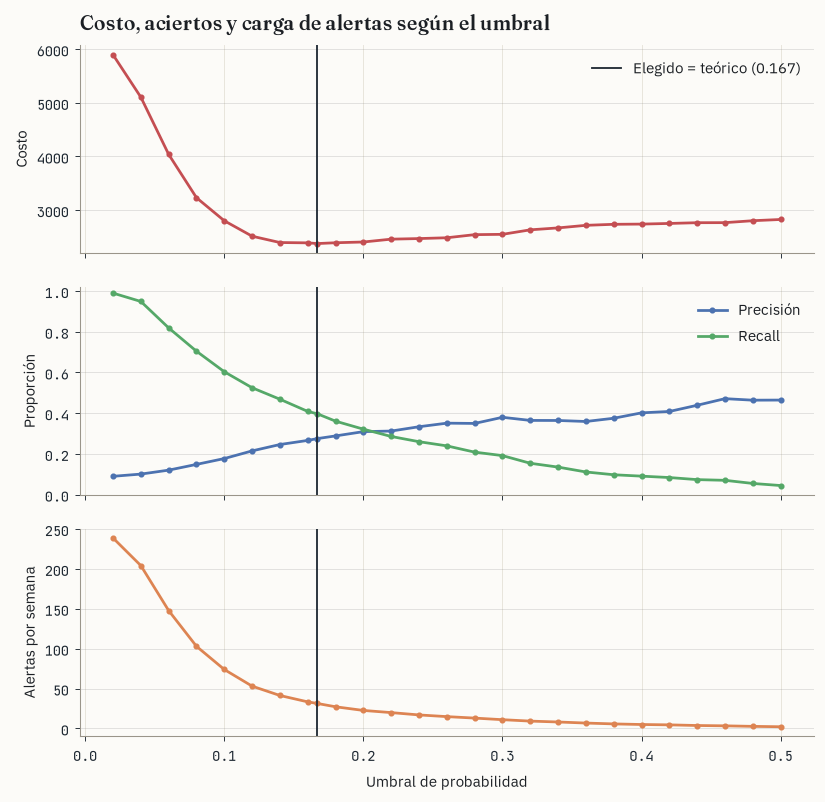

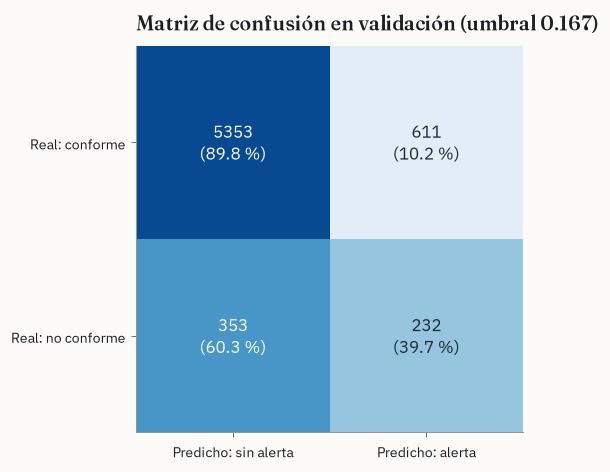

In [59]:
clasificacion.umbral_por_costo(c).mostrar()

## 7. Congelamiento del modelo

Hiperparámetros, configuración, calibración y umbral quedan fijos; el modelo se reajusta con
entrenamiento y validación (si va calibrado, con bloques temporales de todo el desarrollo).

In [60]:
clasificacion.congelar(c).mostrar()

## Parte B · Bayes: ¿qué tan probable es que un positivo sea un falso positivo?

## 8. La idea en palabras y en fórmulas

Un ensayo se describe con su **sensibilidad** s (fracción de contaminadas que da positivo, medida
con controles positivos) y su **especificidad** e (fracción de limpias que da negativo, medida con
controles negativos). Con la **prevalencia** π, el teorema de Bayes da el valor predictivo positivo:

$$\text{VPP} = P(\text{contaminada} \mid +) = \frac{s\,\pi}{s\,\pi + (1-e)(1-\pi)}, \qquad
P(\text{falso positivo} \mid +) = 1 - \text{VPP}.$$

Con prevalencia baja, el término (1 − e)(1 − π) pesa mucho aunque 1 − e sea pequeño: con e = 0.98,
π = 0.05 y s ≈ 0.95, más de una de cada cuatro alarmas es falsa. La prevalencia no se observa; se
observa la tasa de positivos p, y despejando π de p = s π + (1 − e)(1 − π) se obtiene la corrección
de Rogan–Gladen. Si una muestra se reensaya, el posterior del primer resultado hace de previa del
segundo.

## 9. Sensibilidad y especificidad de cada ensayo

Solo controles anteriores al periodo de prueba; intervalos de Wilson al 95 %.

In [61]:
clasificacion.sensibilidad_especificidad(c).mostrar()

Ensayo,Controles +,Sensibilidad,Sens. inf.,Sens. sup.,Controles −,Especificidad,Espec. inf.,Espec. sup.
Pseudomonas aeruginosa,1468,0.920,0.905,0.932,1468,0.986,0.978,0.991
Salmonella spp.,1468,0.897,0.881,0.912,1468,0.995,0.990,0.998
Staphylococcus aureus,1468,0.931,0.917,0.943,1468,0.990,0.983,0.994
coliformes y E. coli,1468,0.937,0.924,0.949,1468,0.980,0.972,0.986
esterilidad,1468,0.963,0.952,0.972,1468,0.980,0.972,0.986
mesófilos aerobios,1468,0.966,0.955,0.974,1468,0.977,0.968,0.983
mohos y levaduras,1468,0.950,0.938,0.960,1468,0.976,0.967,0.983


## 10. VPP por ensayo

La tasa de positivos sale de las muestras aceptadas del desarrollo. La incertidumbre se propaga
con sorteos de las posteriores Beta de sensibilidad, especificidad y tasa de positivos (previa
uniforme y sus conteos), con la semilla del proyecto.

Ensayo,Muestras,Positivos,Tasa de positivos,Sens.,Espec.,Prevalencia corregida,VPP,VPP inf.,VPP sup.,P(falso positivo)
Pseudomonas aeruginosa,2869,195,0.068,0.920,0.986,0.059,0.802,0.685,0.875,0.198
Salmonella spp.,520,23,0.044,0.897,0.995,0.044,0.897,0.761,0.956,0.103
Staphylococcus aureus,2684,100,0.037,0.931,0.990,0.029,0.734,0.543,0.842,0.266
coliformes y E. coli,4773,414,0.087,0.937,0.980,0.073,0.789,0.687,0.855,0.211
esterilidad,1366,70,0.051,0.963,0.980,0.033,0.627,0.428,0.759,0.373
mesófilos aerobios,10625,1071,0.101,0.966,0.977,0.082,0.789,0.702,0.849,0.211
mohos y levaduras,6175,632,0.102,0.950,0.976,0.085,0.787,0.701,0.850,0.213


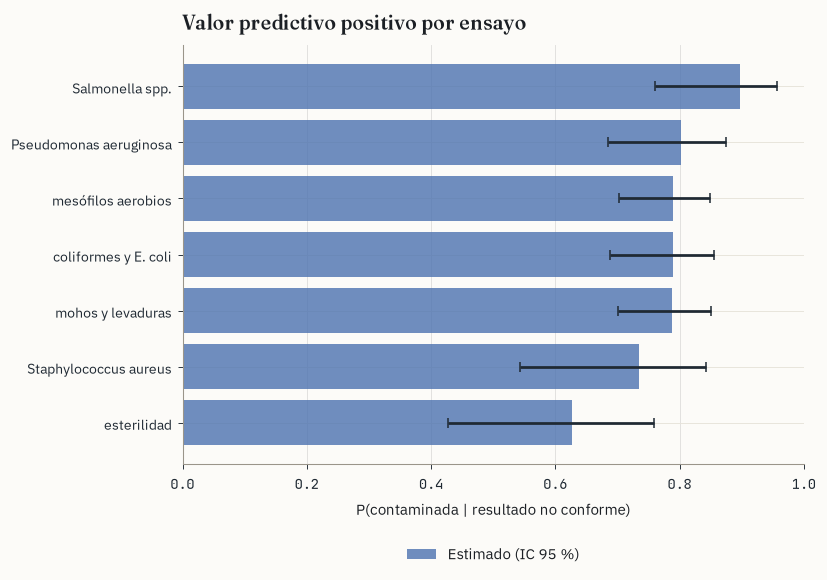

In [62]:
clasificacion.vpp_por_ensayo(c).mostrar()

## 11. VPP por muestra: la previa que aporta el clasificador

El clasificador estima p(x), la tasa de positivos esperada para muestras como x. Aplicando
Rogan–Gladen muestra a muestra se obtiene la previa π(x) y con ella VPP(x) = s · π(x) / p(x). Se
usa el modelo de la parte A ajustado solo con entrenamiento, sobre las muestras de validación.
π(x) = 0 significa que el positivo se explica entero por el error del ensayo.

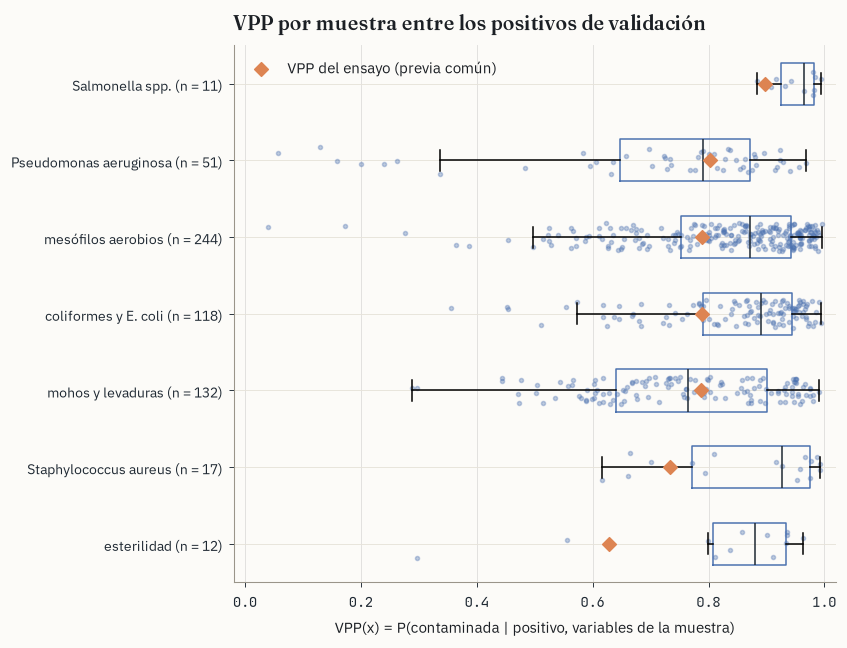

Ensayo,Positivos,VPP(x) medio,Percentil 10,Mediana,Percentil 90
Pseudomonas aeruginosa,51.000,0.715,0.262,0.791,0.923
Salmonella spp.,11.000,0.952,0.908,0.965,0.984
Staphylococcus aureus,17.000,0.862,0.663,0.926,0.989
coliformes y E. coli,118.000,0.849,0.661,0.890,0.967
esterilidad,12.000,0.811,0.581,0.879,0.935
mesófilos aerobios,244.000,0.826,0.623,0.871,0.973
mohos y levaduras,132.000,0.761,0.565,0.765,0.951


In [63]:
clasificacion.vpp_por_muestra(c).mostrar()

## 12. Posterior tras el reensayo

Con dos positivos la confianza sube; con un positivo y un negativo, baja (suponiendo resultados
independientes dada la condición real). El modelo predice además la fracción de reensayos
conformes, P(− | + inicial) = VPP · (1 − s) + (1 − VPP) · e, que se compara con lo observado.

In [64]:
clasificacion.reensayo(c).mostrar()

Ensayo,VPP (un +),"Posterior (+, +)","Posterior (+, −)",Reensayados,Fracción reensayada,Reensayo conforme esperado,Reensayo conforme observado
Pseudomonas aeruginosa,0.802,0.996,0.248,176,0.903,0.260,0.284
Salmonella spp.,0.897,0.999,0.474,21,0.913,0.195,0.429
Staphylococcus aureus,0.734,0.996,0.161,89,0.890,0.314,0.337
coliformes y E. coli,0.789,0.994,0.193,363,0.877,0.256,0.231
esterilidad,0.627,0.988,0.059,62,0.886,0.388,0.484
mesófilos aerobios,0.789,0.994,0.115,927,0.866,0.233,0.227
mohos y levaduras,0.787,0.993,0.158,548,0.867,0.247,0.332


## 13. Auditoría de la simulación

Solo porque los datos son simulados existe una verdad oculta (qué muestra estaba de verdad
contaminada); con datos reales el reensayo es la única referencia, imperfecta.

Ensayo,Sens. estimada,Sens. real,Espec. estimada,Espec. efectiva real,Prevalencia corregida,Prevalencia real,VPP estimado,VPP real,Dentro del IC
Pseudomonas aeruginosa,0.920,0.920,0.986,0.984,0.059,0.059,0.802,0.795,sí
Salmonella spp.,0.897,0.900,0.995,0.992,0.044,0.033,0.897,0.739,no
Staphylococcus aureus,0.931,0.930,0.990,0.986,0.029,0.026,0.734,0.670,sí
coliformes y E. coli,0.937,0.940,0.980,0.980,0.073,0.075,0.789,0.802,sí
esterilidad,0.963,0.960,0.980,0.970,0.033,0.026,0.627,0.471,sí
mesófilos aerobios,0.966,0.970,0.977,0.979,0.082,0.083,0.789,0.795,sí
mohos y levaduras,0.950,0.950,0.976,0.970,0.085,0.076,0.787,0.696,no


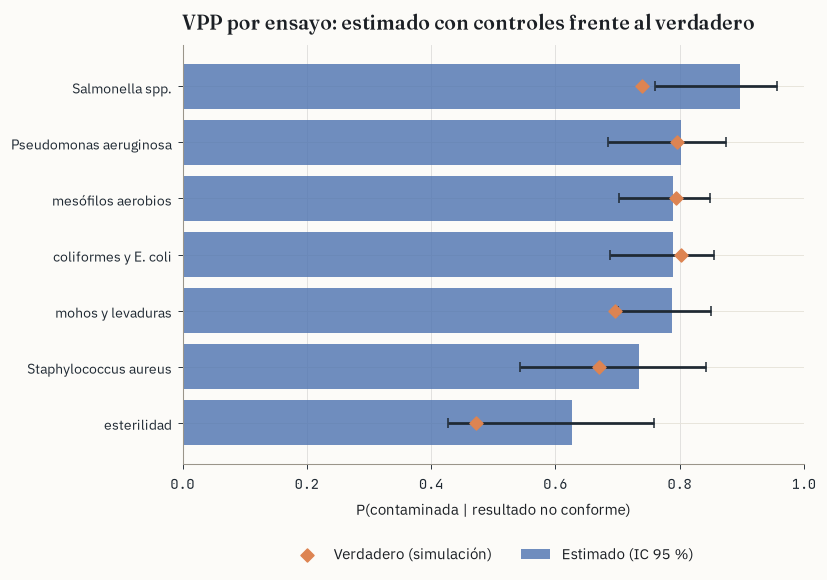

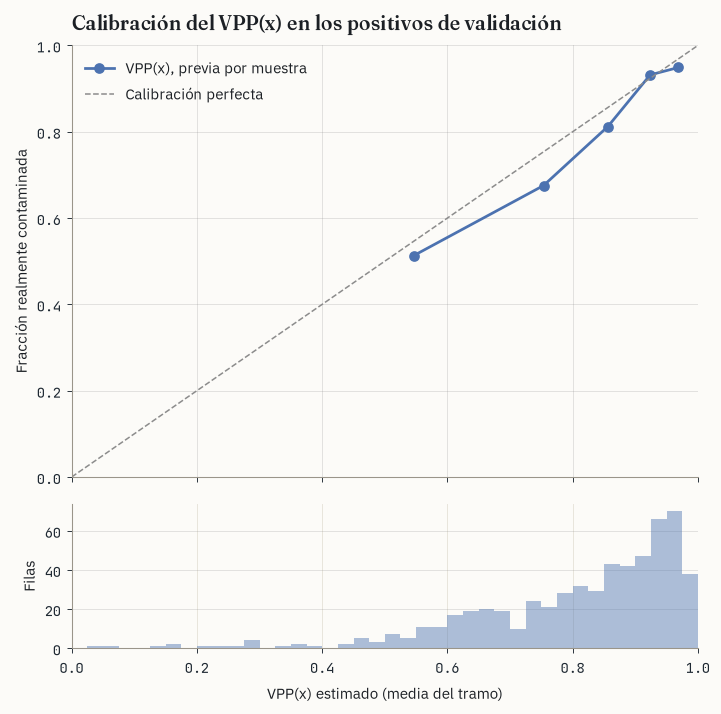

In [65]:
clasificacion.auditoria(c).mostrar()

## 14. Una regla simple para el reensayo

En la etapa 03, «falso positivo entre los no conformes» quedó fuera porque una sola variable, la
razón logarítmica entre el recuento y el límite, explicaba casi todo. Aquí se lee esa relación por
tramos con los no conformes reensayados del desarrollo.

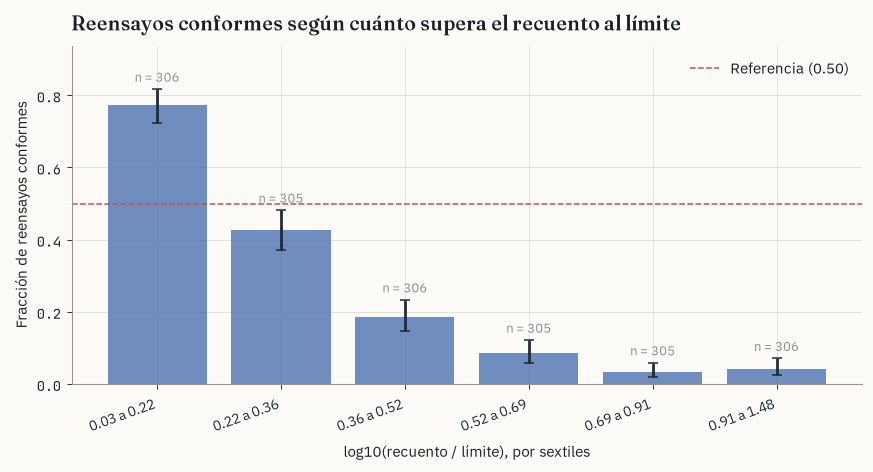

In [66]:
clasificacion.regla_reensayo(c).mostrar()

In [67]:
clasificacion.terminar(c)

# 06 · Agrupamiento: perfiles de muestra y segmentos de clientes

Aquí no hay una respuesta correcta que predecir: se busca si las muestras (y, en un segundo
análisis, los clientes) se reparten en grupos con un perfil reconocible y útil para la operación.
Se usan los dos métodos del curso, K-means y DBSCAN, sobre tablas construidas solo con fechas de
desarrollo.

In [68]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import agrupamiento

iniciar_etapa("06_agrupamiento")
c = agrupamiento.iniciar()
mostrar(c.encabezado)

## 1. Qué se agrupa y con qué reglas

El cribado eligió un análisis con su regla fija; además se conserva uno complementario, fuera de la
regla, porque al laboratorio le interesan sus clientes. Las reglas de decisión se fijan antes de ver
resultados, para que ningún número de grupos se acomode a lo que se quiere ver. Los datos son
simulados: los grupos describen el mecanismo de la simulación y sus lecturas son un ejercicio de
método.

In [69]:
agrupamiento.reglas(c).mostrar()

## 2. Análisis seleccionado: perfiles de muestra

### 2.1 Preparación: por qué escalar

K-means y DBSCAN deciden con distancias euclidianas, que suman diferencias en unidades distintas
(mililitros, horas, días, UFC): sin escalar, la variable de mayor varianza decide casi sola quién
está cerca de quién. El estadístico de Hopkins compara la distancia entre vecinos reales con la de
puntos al azar (por encima de 0.5 hay tendencia a agruparse, sin decir cuántos grupos).

In [70]:
agrupamiento.preparacion(c, "seleccionado").mostrar()

### 2.2 K-means: número de grupos

La inercia siempre baja al aumentar k, así que el codo solo orienta; la elección se apoya en la
silueta, que sí penaliza partir un grupo que no debía partirse.

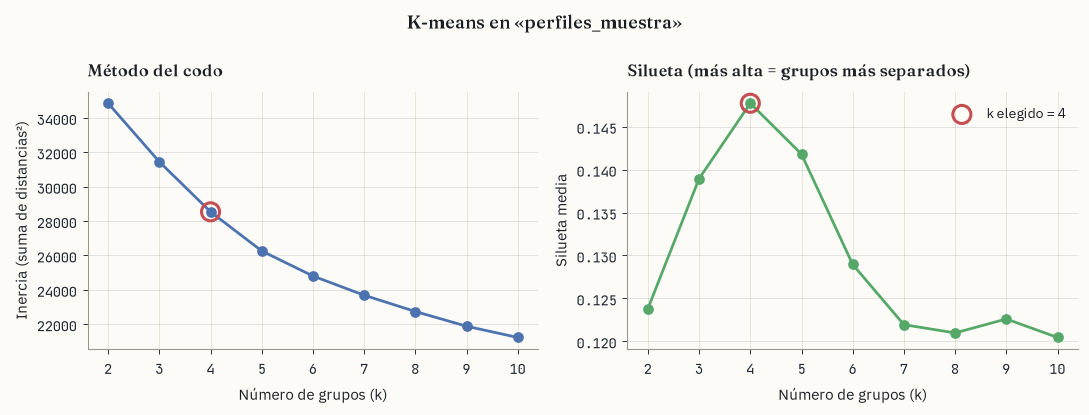

In [71]:
agrupamiento.kmeans(c, "seleccionado").mostrar()

### 2.3 DBSCAN: grupos por densidad

DBSCAN recibe un radio (eps) y un mínimo de vecinos (min_samples) y deja como ruido los puntos sin
suficientes vecinos cerca. La curva de k-distancias orienta la franja de eps. Los puntos de ruido no
son errores: son los casos que vale la pena revisar a mano.

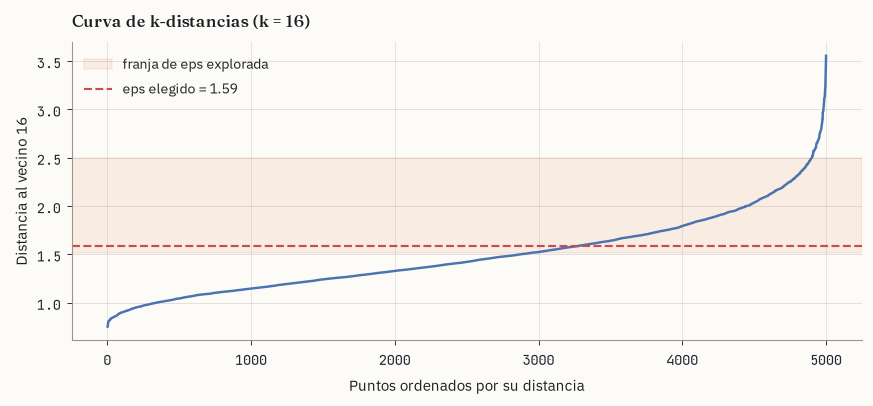

eps,min_samples,Grupos,Ruido,Silueta (sin ruido)
1.36,8,4,0.199,0.103
1.42,8,3,0.156,0.149
1.48,8,3,0.120,0.280
1.55,8,2,0.089,0.313
1.64,8,2,0.060,0.309
1.75,8,2,0.037,0.307
1.93,8,1,0.018,—
2.31,8,1,0.003,—
1.52,16,2,0.170,0.319
1.59,16,2,0.127,0.314


id_muestra,id_cliente,matriz,ensayo,volumen de muestra,hora de recepción,temperatura de transporte,horas de transporte,días prometidos,carga del día,control ambiental,días de entrega,Variable más apartada
M005080,C078,superficie,mesófilos aerobios,1079.00,12.63,3.80,3.00,8.00,12.00,3.00,5.00,volumen de muestra (+10.1 DE)
M000334,C048,producto terminado,mohos y levaduras,1072.00,8.06,6.20,4.60,11.00,38.00,1.00,8.00,volumen de muestra (+10.0 DE)
M010157,C061,producto terminado,mohos y levaduras,976.00,7.45,7.30,4.30,11.00,42.00,1.00,8.00,volumen de muestra (+9.0 DE)
M026629,C195,materia prima,mohos y levaduras,931.00,11.23,6.10,4.60,11.00,67.00,0.00,9.00,volumen de muestra (+8.5 DE)
M009958,C075,producto terminado,esterilidad,336.00,9.68,8.00,42.60,20.00,62.00,2.00,36.00,días de entrega (+7.8 DE)
M025255,C143,materia prima,esterilidad,131.00,15.20,18.10,4.10,20.00,53.00,1.00,36.00,días de entrega (+7.8 DE)
M020378,C168,producto terminado,mesófilos aerobios,864.00,8.09,6.70,5.00,5.00,58.00,2.00,3.00,volumen de muestra (+7.7 DE)
M008353,C075,producto terminado,esterilidad,41.00,15.72,21.40,21.10,20.00,40.00,0.00,35.00,días de entrega (+7.5 DE)


In [72]:
agrupamiento.dbscan(c, "seleccionado").mostrar()

### 2.4 K-means frente a DBSCAN

El índice de Rand ajustado (ARI) vale 1 si dos particiones coinciden y cerca de 0 si se parecen
como dos particiones al azar. La proyección en dos componentes principales solo sirve para dibujar.

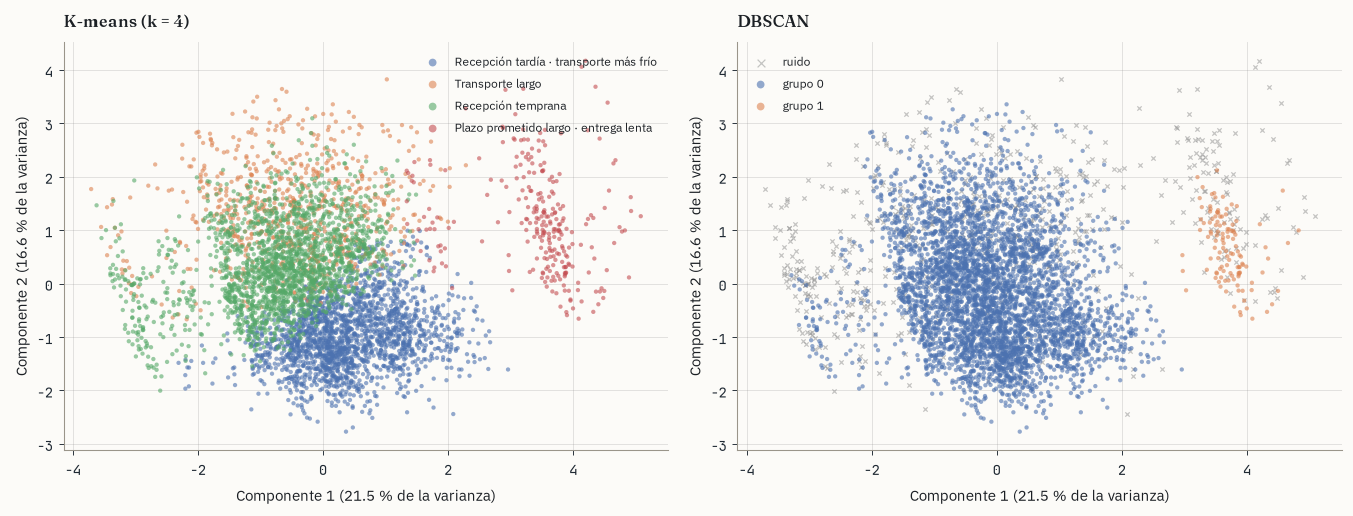

In [73]:
agrupamiento.comparar_particiones(c, "seleccionado").mostrar()

### 2.5 Perfiles: de grupos numerados a perfiles con nombre

El perfil se calcula sobre las variables originales, y cada media se expresa en desviaciones
estándar respecto a la general, lo que permite nombrar el grupo por las variables en que más se
aparta. Los nombres salen del código, no de una lectura a ojo.

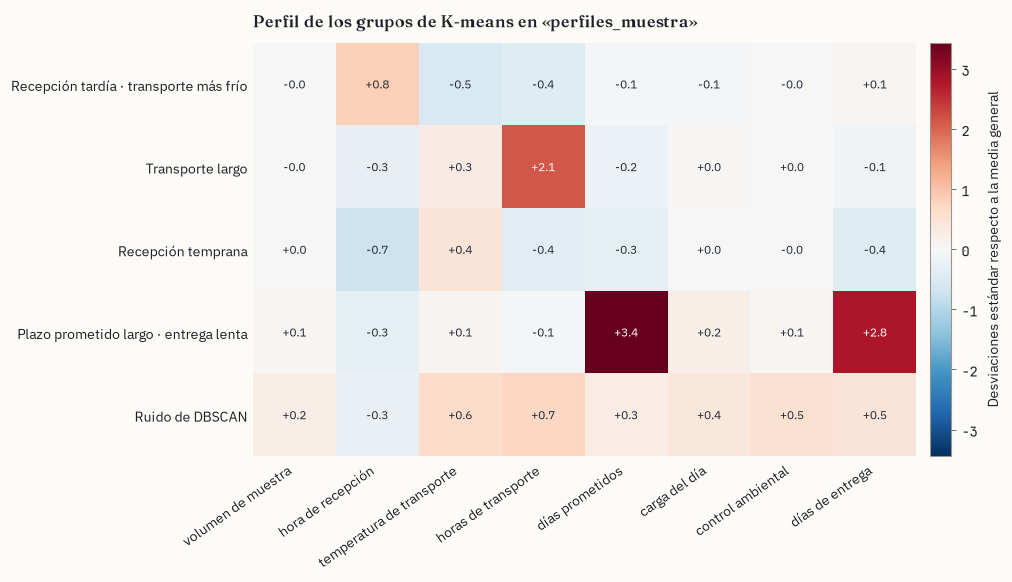

Grupo,n,Proporción,Variables que lo distinguen,Matriz más frecuente,Ensayo más frecuente,Sector más frecuente
Recepción tardía · transporte más frío,2026,0.405,hora de recepción +0.8 DE; temperatura de transporte -0.5 DE,superficie,mesófilos aerobios,cosmético
Transporte largo,753,0.151,horas de transporte +2.1 DE,producto terminado,mesófilos aerobios,cosmético
Recepción temprana,1953,0.391,hora de recepción -0.7 DE,producto terminado,mesófilos aerobios,cosmético
Plazo prometido largo · entrega lenta,268,0.054,días prometidos +3.4 DE; días de entrega +2.8 DE,producto terminado,esterilidad,central de mezclas


Variable,Recepción tardía · transporte más frío,Transporte largo,Recepción temprana,Plazo prometido largo · entrega lenta
volumen de muestra,140.02,140.03,144.21,147.28
hora de recepción,14.11,11.52,10.52,11.47
temperatura de transporte,6.29,11.15,11.99,9.94
horas de transporte,3.98,29.17,4.58,7.67
días prometidos,8.85,8.45,8.17,18.70
carga del día,45.28,46.75,46.31,49.78
control ambiental,1.88,1.88,1.86,2.01
días de entrega,7.31,6.67,5.57,17.40


In [74]:
agrupamiento.perfiles(c, "seleccionado").mostrar()

## 3. Análisis complementario: segmentos de clientes

No ganó la regla de cribado, pero responde la pregunta de negocio más cercana a una decisión
comercial (qué tipos de cliente atiende el laboratorio). Se siguen exactamente las mismas reglas.
Con pocas filas y muchas variables la densidad se diluye, y es esperable que DBSCAN no logre separar
grupos que K-means sí reparte.

In [75]:
agrupamiento.preparacion(c, "complementario").mostrar()

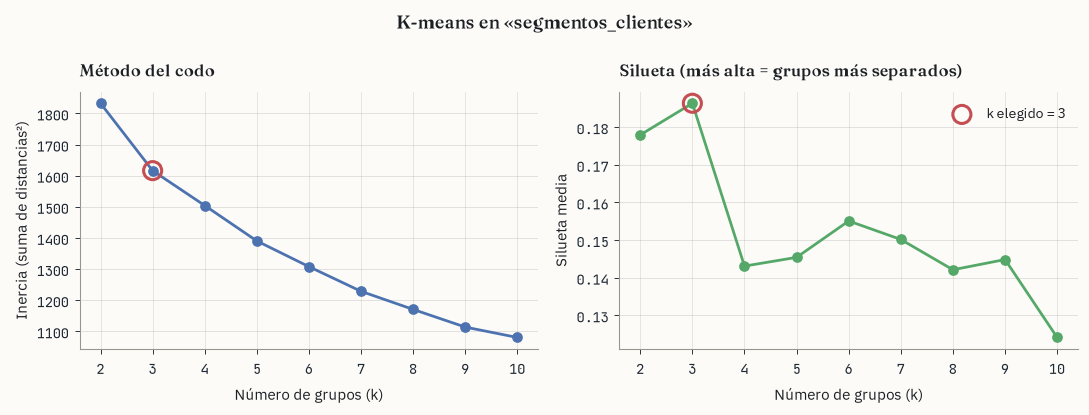

In [76]:
agrupamiento.kmeans(c, "complementario").mostrar()

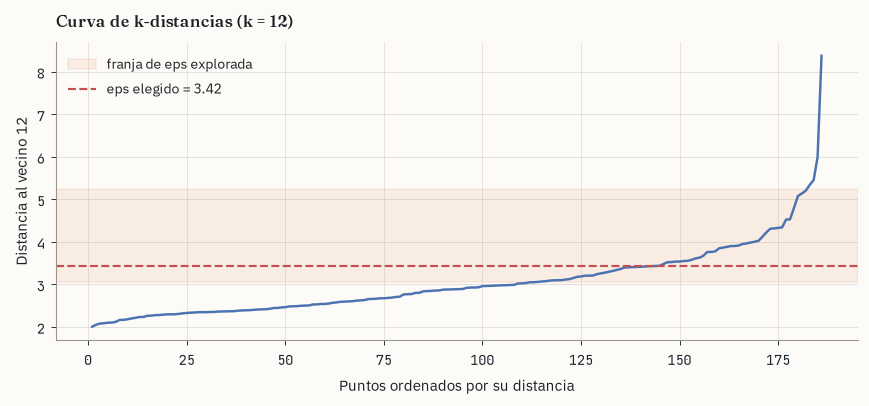

eps,min_samples,Grupos,Ruido,Silueta (sin ruido)
3.04,12,1,0.145,—
3.12,12,1,0.134,—
3.29,12,1,0.108,—
3.42,12,1,0.075,—
3.55,12,1,0.059,—
3.88,12,1,0.027,—
4.24,12,1,0.011,—
5.24,12,1,0.005,—
3.40,24,1,0.102,—
3.49,24,1,0.086,—


id_cliente,muestras,volumen mensual,tamaño de lote,variedad de productos,variedad de ensayos,urgencias,muestreo en planta,no conformidad,entregas tardías,temperatura de llegada,irregularidad de envíos,estacionalidad,antigüedad,Variable más apartada
C026,24.00,1.33,2.40,7.00,5.00,0.00,0.29,0.04,0.25,11.16,0.56,0.92,34.00,estacionalidad (+8.2 DE)
C025,26.00,1.34,3.25,7.00,5.00,0.31,0.00,0.19,0.27,6.85,0.55,0.61,38.00,estacionalidad (+4.8 DE)
C198,54.00,0.83,9.00,4.00,5.00,0.15,0.00,0.00,0.08,15.64,0.72,0.31,243.00,tamaño de lote (+4.5 DE)
C143,121.00,0.53,1.83,7.00,2.00,0.25,0.00,0.13,0.17,16.21,1.54,0.15,1499.00,variedad de ensayos (-4.4 DE)
C194,40.00,0.08,5.00,5.00,2.00,0.00,0.00,0.05,0.11,19.12,0.69,0.18,1089.00,variedad de ensayos (-4.4 DE)
C213,25.00,0.83,5.00,3.00,2.00,0.20,0.00,0.08,0.20,10.37,0.61,0.32,115.00,variedad de ensayos (-4.4 DE)
C182,16.00,0.63,2.29,7.00,5.00,0.06,0.00,0.31,0.44,5.88,0.55,0.38,165.00,entregas tardías (+4.3 DE)
C131,41.00,1.34,6.83,3.00,5.00,0.00,0.63,0.07,0.17,7.54,0.92,0.50,62.00,estacionalidad (+3.7 DE)


In [77]:
agrupamiento.dbscan(c, "complementario").mostrar()

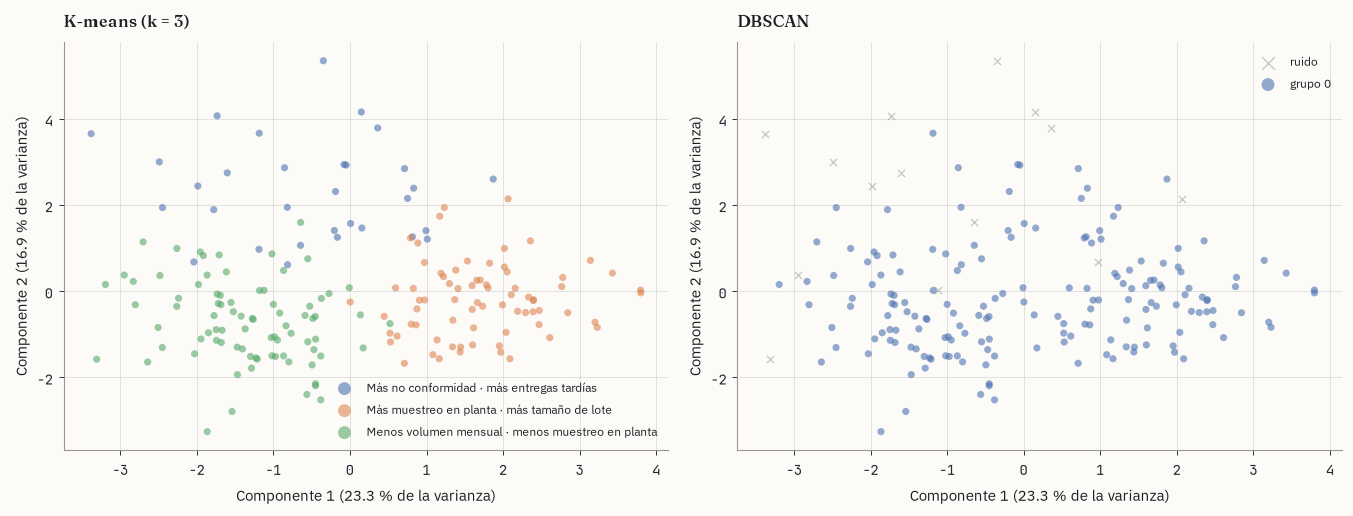

In [78]:
agrupamiento.comparar_particiones(c, "complementario").mostrar()

### Segmentos de clientes y su lectura comercial

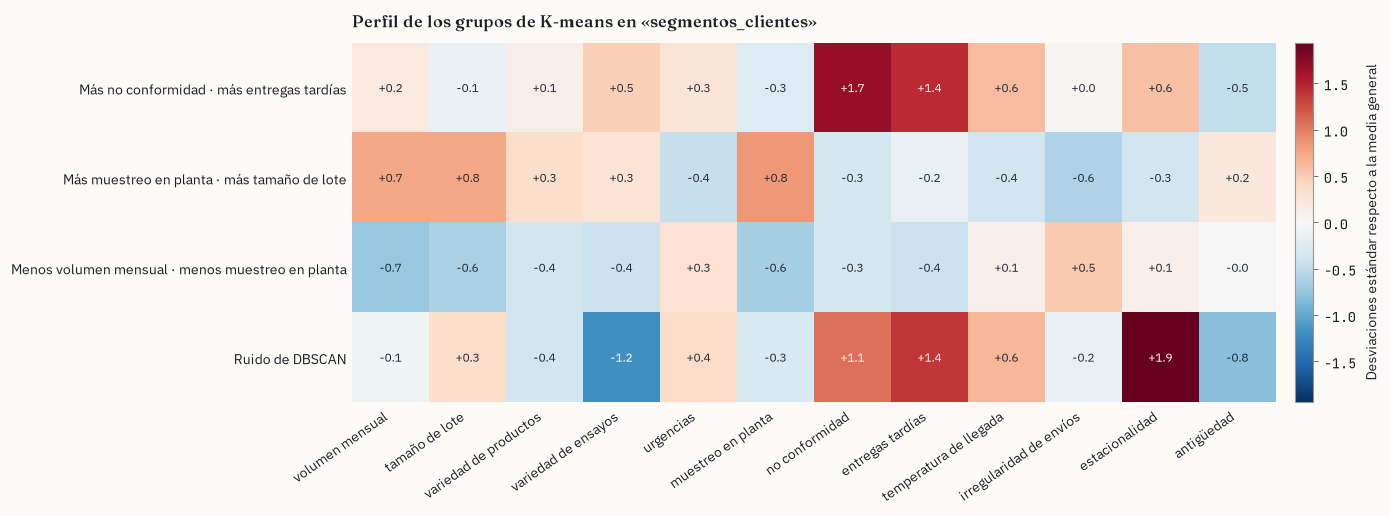

Grupo,n,Proporción,Variables que lo distinguen
Más no conformidad · más entregas tardías,31,0.167,no conformidad +1.7 DE; entregas tardías +1.4 DE; temperatura de llegada +0.6 DE; estacionalidad +0.6 DE
Más muestreo en planta · más tamaño de lote,73,0.392,muestreo en planta +0.8 DE; tamaño de lote +0.8 DE; volumen mensual +0.7 DE; irregularidad de envíos -0.6 DE
Menos volumen mensual · menos muestreo en planta,82,0.441,volumen mensual -0.7 DE; muestreo en planta -0.6 DE; tamaño de lote -0.6 DE; irregularidad de envíos +0.5 DE


Variable,Más no conformidad · más entregas tardías,Más muestreo en planta · más tamaño de lote,Menos volumen mensual · menos muestreo en planta
volumen mensual,0.61,0.87,0.16
tamaño de lote,2.64,3.84,1.95
variedad de productos,6.45,7.18,4.95
variedad de ensayos,5.23,5.10,4.65
urgencias,0.16,0.06,0.17
muestreo en planta,0.11,0.41,0.01
no conformidad,0.22,0.07,0.07
entregas tardías,0.24,0.12,0.11
temperatura de llegada,12.27,8.40,10.27
irregularidad de envíos,0.91,0.74,1.03


Segmento,Clientes,Proporción de clientes,Proporción de muestras,No conformidad,Entregas tardías
Más no conformidad · más entregas tardías,31,0.167,0.114,0.212,0.203
Más muestreo en planta · más tamaño de lote,73,0.392,0.736,0.071,0.119
Menos volumen mensual · menos muestreo en planta,82,0.441,0.150,0.069,0.104


In [79]:
agrupamiento.perfiles(c, "complementario").mostrar()

### Auditoría con la simulación

La simulación asignó a cada cliente un segmento latente que el laboratorio real no conocería; solo
por eso se puede revisar si los grupos encontrados lo recuperan.

In [80]:
agrupamiento.auditoria(c).mostrar()

Segmento latente (simulación),Menos volumen mensual · menos muestreo en planta,Más muestreo en planta · más tamaño de lote,Más no conformidad · más entregas tardías
crítico urgente,18,8,12
estacional,13,14,5
industrial regular,2,39,5
pyme esporádica,49,12,9


## 4. Silueta del cribado frente a la silueta de esta etapa

Las dos cuentas difieren en las filas (el cribado usa solo entrenamiento; aquí, todo el desarrollo)
y en el preprocesamiento (el cribado solo escala; aquí se aplica antes log1p). Para separar los dos
efectos se recalcula la mejor silueta con las filas de esta etapa pero sin log1p.

In [81]:
agrupamiento.silueta_cribado(c).mostrar()

Análisis,Filas (cribado),Filas (etapa 06),k (cribado),Silueta (cribado),"k (filas 06, sin log1p)","Silueta (filas 06, sin log1p)",k (etapa 06),Silueta (etapa 06),Puntaje de la regla (cribado),Puntaje con la silueta de la etapa 06
perfiles_muestra,3834,5000,2,0.433,2,0.434,4,0.148,0.144,0.049
segmentos_clientes,177,186,2,0.182,3,0.183,3,0.186,0.122,0.124


## 5. Síntesis

In [82]:
agrupamiento.sintesis(c).mostrar()

In [83]:
agrupamiento.terminar(c)

# 07 · Evaluación final: abrir la prueba una sola vez

Las etapas 04, 05 y 06 dejaron modelos congelados (variables, hiperparámetros, calibración y
umbral) sin mirar nunca el periodo de prueba. Aquí se abre ese periodo una sola vez, con
`leer_prueba`, que deja constancia de cada lectura, y se mide lo que los modelos hacen con datos que
nadie usó para decidir. Primero se muestra lo congelado, después se abre la prueba y al final se
comparan las dos cosas, sin reajustar ni reelegir nada.

In [84]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import evaluacion_final as final

iniciar_etapa("07_evaluacion_final")
c = final.iniciar()
mostrar(c.encabezado)

## 1. Lo que quedó congelado

Desde aquí no se cambia nada: ni el modelo, ni las variables, ni los hiperparámetros, ni la
calibración, ni el umbral.

In [85]:
final.congelado(c).mostrar()

Análisis,Tipo,Modelo,Variables,Hiperparámetros,Calibración y umbral,Validación
carga_diaria,regresión,Regresión lineal,grupo ampliado (16),ninguno (mínimos cuadrados),no aplica,"RMSE 14.59, habilidad 0.249"
no_conforme_recepcion,clasificación,Regresión logística,grupo ampliado (51),C = 10.0,"sigmoide, umbral 0.167","ROC-AUC 0.721, costo 2376, precisión 0.275"


## 2. Apertura de la prueba

Se leen tres bloques: la carga diaria (regresión), las muestras en recepción (clasificación y
Bayes) y los no conformes reensayados (VPP y regla de reensayo). Cada lectura queda registrada en
`artefactos/_etapas/lecturas_prueba.log`.

In [86]:
final.abrir_prueba(c).mostrar()

## 3. Regresión: ¿cuántas muestras llegarán mañana?

El modelo congelado predice cada día con la información de la víspera y se compara con las mismas
referencias ingenuas de la etapa 04; la habilidad se mide frente a la misma referencia de entonces.

In [87]:
final.regresion(c).mostrar()

Predictor,MAE,RMSE,R2,Habilidad
Regresión lineal,9.80,12.47,0.529,0.334
base_dia_anterior,20.47,26.04,-1.053,-0.390
base_media_5,14.65,18.73,-0.062,0.000


Métrica,Validación,Prueba,Prueba inf.,Prueba sup.
RMSE,14.591,12.466,11.201,13.658
MAE,11.030,9.802,8.716,10.856
R²,0.367,0.529,0.402,0.622
Habilidad,0.249,0.334,0.247,0.408


### 3.1 Residuos, fin de año y operación

La tolerancia práctica es la misma de la etapa 04 (en muestras por día), de forma que la prueba no
mueve la vara con que se juzga.

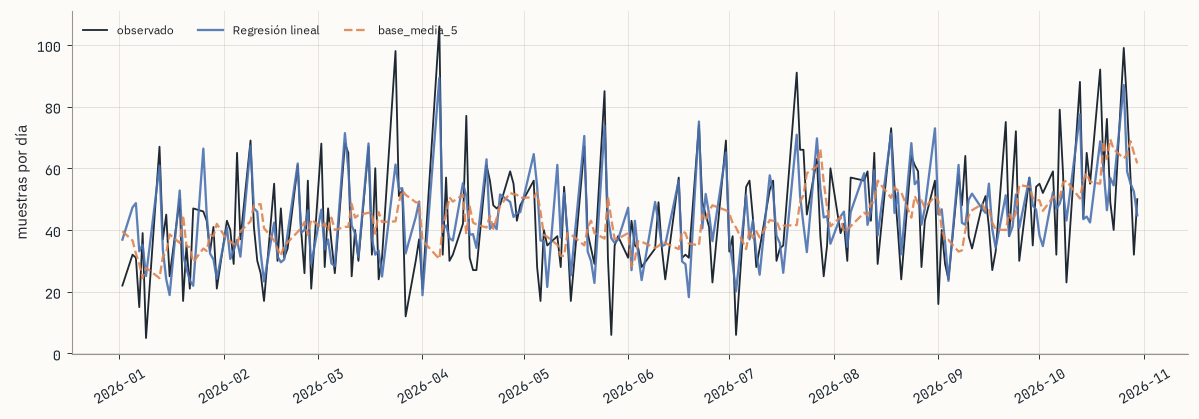

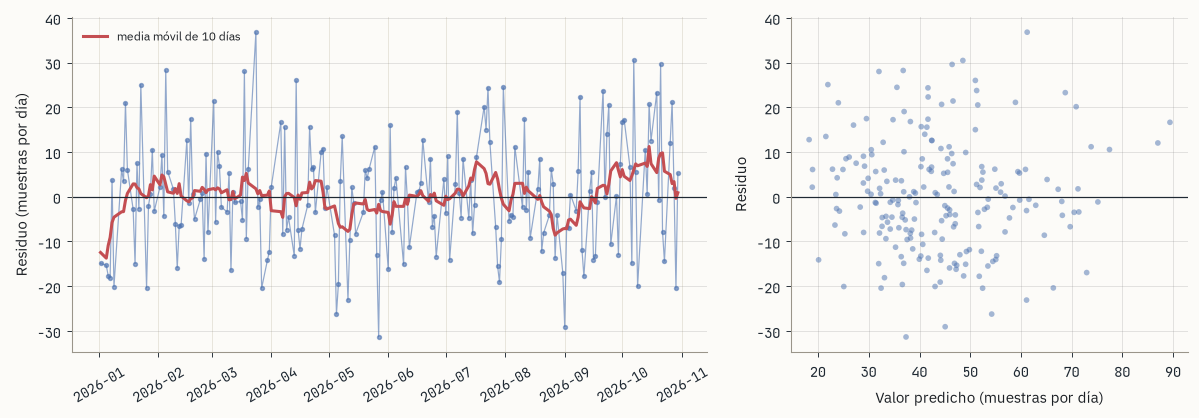

In [88]:
final.regresion_diagnostico(c).mostrar()

## 4. Clasificación: ¿qué muestras están en riesgo?

Cada muestra de prueba recibe una probabilidad y la alerta se levanta con el umbral de validación.
Al lado del costo van la precisión y las alertas por semana, porque un costo bajo con demasiadas
falsas alarmas no sirve en recepción.

Métrica,Validación,Prueba,Prueba inf.,Prueba sup.
ROC-AUC,0.721,0.724,0.705,0.743
Precisión media,0.245,0.243,0.216,0.276
Brier,0.075,0.075,0.072,0.080
Precisión,0.275,0.270,0.242,0.299
Recall,0.397,0.325,0.293,0.357
F1,0.325,0.295,0.267,0.324
Costo por muestra,0.363,0.381,0.358,0.409


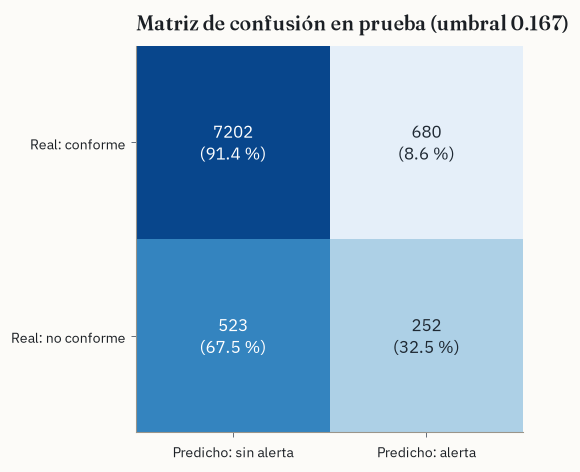

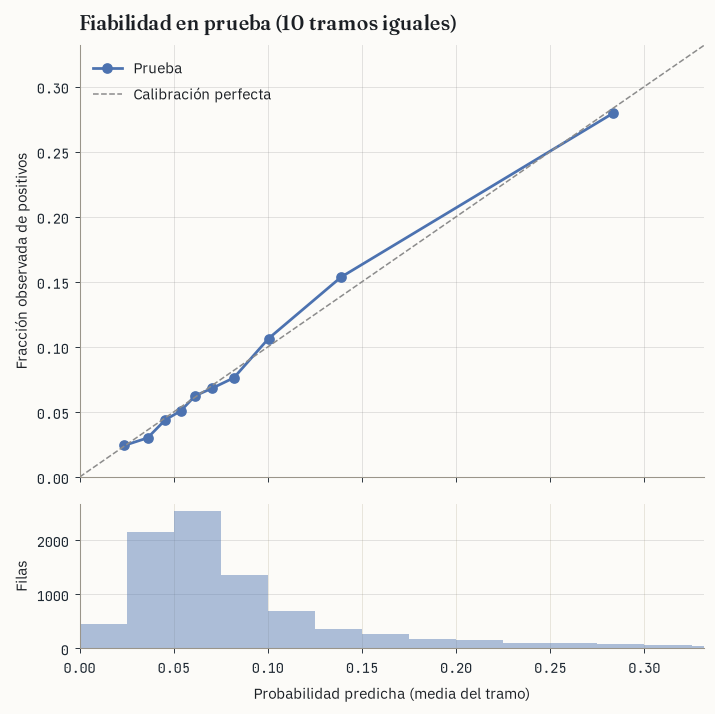

In [89]:
final.clasificacion(c).mostrar()

### 4.1 Retrospectiva: el umbral que habría convenido

Solo por transparencia: un umbral elegido en la prueba estaría ajustado a ella y su costo sería
optimista. Esta celda no decide nada.

In [90]:
final.retrospectiva(c).mostrar()

## 5. Bayes en la prueba: ¿qué tan probable es que un positivo sea falso?

Con la sensibilidad y la especificidad del desarrollo y la probabilidad del clasificador como previa
de cada muestra se calcula el VPP(x) de cada positivo; la referencia observable es el reensayo.

In [91]:
final.bayes_prueba(c).mostrar()

Ensayo,Positivos,VPP del ensayo (desarrollo),VPP(x) medio,Reensayados,Reensayo conforme esperado,Reensayo conforme observado
Pseudomonas aeruginosa,53,0.802,0.729,50,0.321,0.260
Salmonella spp.,3,0.897,0.917,2,0.141,0.000
Staphylococcus aureus,35,0.734,0.827,32,0.218,0.344
coliformes y E. coli,148,0.789,0.828,131,0.217,0.252
esterilidad,22,0.627,0.740,19,0.301,0.421
mesófilos aerobios,319,0.789,0.807,285,0.220,0.140
mohos y levaduras,195,0.787,0.763,172,0.269,0.326


### 5.1 Auditoría de la simulación

Solo existe porque el generador guardó la verdad oculta; con datos reales no aplica.

In [92]:
final.auditoria(c).mostrar()

Ensayo,Positivos,VPP del ensayo (desarrollo),VPP(x) medio,Fracción realmente contaminada
Pseudomonas aeruginosa,53,0.802,0.729,0.792
Salmonella spp.,3,0.897,0.917,1.000
Staphylococcus aureus,35,0.734,0.827,0.714
coliformes y E. coli,148,0.789,0.828,0.797
esterilidad,22,0.627,0.740,0.591
mesófilos aerobios,319,0.789,0.807,0.875
mohos y levaduras,195,0.787,0.763,0.718


### 5.2 La regla de reensayo en la prueba

Se aplica el mismo borde fijado en la etapa 05, leído del artefacto, a los reensayos de prueba.

In [93]:
final.regla_reensayo(c).mostrar()

Periodo,Conformes con razón ≤ 0.22,Conformes con razón > 0.22,Fracción de conformes capturada
Desarrollo,0.777,0.152,0.510
Prueba,0.774,0.120,0.545


## 6. Agrupamiento

El agrupamiento no se evalúa en la prueba por diseño: no hay respuesta correcta con que comparar.
Se resume lo que dejó la etapa 06.

In [94]:
final.agrupamiento(c).mostrar()

## 7. Resumen para la presentación

Las cifras son las de la prueba, salvo donde se indica otra cosa.

In [95]:
final.resumen(c).mostrar()

Pregunta del laboratorio,Respuesta,Evidencia,Limitación
¿Cuántas muestras llegarán mañana?,Regresión lineal con un error típico de 9.8 muestras sobre una media de 44.1,RMSE 12.47 en prueba (14.59 en validación); habilidad 0.334,el 38 % de los días queda fuera de la tolerancia
¿Qué muestras están en riesgo?,"alerta en recepción con umbral 0.167, unas 21 por semana",AUC 0.724; costo 3295 frente a 3875 sin modelo,solo el 27 % de las alertas acierta
¿Qué tan probable es un falso positivo?,"uno de cada 5 positivos, según controles y clasificador; reensayar si el recuento es menor que 1.66 veces el límite",reensayo conforme 23.3 % observado frente a 24.1 % esperado,el reensayo no es una verdad: también falla
¿Qué grupos existen?,4 perfiles de muestra y 3 segmentos de clientes,"silueta 0.148, Hopkins 0.714",fronteras difusas; uso descriptivo


In [96]:
final.terminar(c)